**Pneumonia Detection from Chest X-Ray Images Using Attention-Enhanced DenseNet121**

This notebook develops, trains, fine-tunes, evaluates and explains **one** proposed model:
**DenseNet121 (ImageNet) + CBAM (Convolutional Block Attention Module)** for binary classification
(`NORMAL` vs `PNEUMONIA`) of chest X-ray images.

> DenseNet121 and CBAM are existing, published building blocks. The contribution here is the *combination*
> (CBAM placed on the final DenseNet121 feature maps), a leakage-aware evaluation protocol, and a
> Grad-CAM explainability analysis - not a claim that either component is new.

**Environment:** Windows 11 - VS Code - Jupyter (`.ipynb`) - Python - TensorFlow/Keras - NVIDIA RTX 3050 Laptop GPU (6 GB).

### Contents
1. Environment and GPU check
2. Configuration and project paths
3. Dataset download (kagglehub) and location
4. Dataset analysis
5. Leakage-aware train / validation / test split
6. Shared module `inference_utils.py` (preprocessing, CBAM layers, Grad-CAM, prediction)
7. `tf.data` pipelines, augmentation and class weights
8. Model architecture (DenseNet121 + CBAM) and pre-training self-tests
9. Stage 1 - feature extraction
10. Stage 2 - fine-tuning
11. Training curves
12. Evaluation on the untouched test set
13. Grad-CAM explainability
14. Single-image prediction
15. Saving artifacts and final verification

## 1. Environment and GPU check

We print the Python / TensorFlow versions and check whether TensorFlow can really see the GPU.
Having an NVIDIA GPU does **not** mean TensorFlow can use it:

* On **native Windows**, TensorFlow **2.10 was the last release with GPU support**. Newer versions run on the CPU only.
* For GPU training with a current TensorFlow on Windows, use **WSL2** (Ubuntu) and install `tensorflow[and-cuda]`,
  then open the project from VS Code with the *WSL* extension. See the README.

If no GPU is visible the notebook prints a warning and continues on the CPU instead of crashing
(training will then be much slower).

In [1]:
import os
import sys
import platform
import random
import json
import time
import shutil
import hashlib
import re
import subprocess
import tempfile
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display

import sklearn
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve,
)

import tensorflow as tf
from tensorflow import keras

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

print("Platform    :", platform.platform())
print("Python      :", sys.version.split()[0])
print("TensorFlow  :", tf.__version__)
print("Keras       :", keras.__version__)
print("NumPy       :", np.__version__, "| pandas:", pd.__version__, "| scikit-learn:", sklearn.__version__,
      "| matplotlib:", matplotlib.__version__)

TF_MAJOR_MINOR = tuple(int(p) for p in tf.__version__.split(".")[:2])
if TF_MAJOR_MINOR < (2, 16):
    print("\nWARNING: this notebook is written for TensorFlow >= 2.16 (Keras 3). "
          "Older versions may work but are not the target - consider `pip install -U tensorflow`.")

C:\Users\Vibha Poojary\AppData\Roaming\Python\Python310\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.5.0) or chardet (7.4.1)/charset_normalizer (3.4.4) doesn't match a supported version!
  warnings.warn(


Platform    : Windows-10-10.0.26100-SP0
Python      : 3.10.0
TensorFlow  : 2.20.0
Keras       : 3.12.0
NumPy       : 1.26.4 | pandas: 2.3.3 | scikit-learn: 1.7.2 | matplotlib: 3.10.7


In [2]:
def run_cmd(cmd):
    """Run a shell command and return stdout, or None if it is unavailable / fails."""
    try:
        out = subprocess.run(cmd, capture_output=True, text=True, timeout=15)
        return out.stdout.strip() if out.returncode == 0 else None
    except (FileNotFoundError, subprocess.TimeoutExpired, OSError):
        return None


print("TensorFlow built with CUDA :", tf.test.is_built_with_cuda())
try:
    build_info = tf.sysconfig.get_build_info()
    print("Build CUDA / cuDNN         :", build_info.get("cuda_version", "n/a"), "/", build_info.get("cudnn_version", "n/a"))
except Exception:
    pass

gpus = tf.config.list_physical_devices("GPU")
GPU_AVAILABLE = len(gpus) > 0
print(f"GPUs visible to TensorFlow : {len(gpus)}")

if GPU_AVAILABLE:
    for i, gpu in enumerate(gpus):
        try:
            tf.config.experimental.set_memory_growth(gpu, True)
            print(f"  GPU {i}: memory growth enabled")
        except RuntimeError as exc:  # must be set before the GPU is initialised
            print(f"  GPU {i}: could not enable memory growth ({exc})")
        try:
            details = tf.config.experimental.get_device_details(gpu)
            print(f"  GPU {i}: {details.get('device_name', gpu.name)} | compute capability {details.get('compute_capability')}")
        except Exception as exc:
            print(f"  GPU {i}: {gpu.name} (device details unavailable: {exc})")
    try:
        mem = tf.config.experimental.get_memory_info("GPU:0")
        print(f"  GPU memory in use by TensorFlow: {mem['current'] / 1024**2:.0f} MB (peak {mem['peak'] / 1024**2:.0f} MB)")
    except Exception:
        pass

smi = run_cmd(["nvidia-smi", "--query-gpu=name,memory.total,memory.used,driver_version", "--format=csv,noheader"])
if smi:
    print("nvidia-smi                 :", smi.replace("\n", " | "))

if not GPU_AVAILABLE:
    print("\n" + "=" * 78)
    print("WARNING: TensorFlow cannot see a GPU. Training will run on the CPU and will be SLOW")
    print("(expect hours instead of minutes for the full two-stage training).")
    if smi:
        print("An NVIDIA GPU IS present, but this TensorFlow install cannot use it.")
    print("Native Windows builds of TensorFlow 2.11+ are CPU-only. For GPU training use WSL2 +")
    print("`pip install \"tensorflow[and-cuda]\"` (see README). The notebook will continue on the CPU.")
    print("=" * 78)

try:
    import psutil
    vm = psutil.virtual_memory()
    print(f"System RAM                 : {vm.total / 1024**3:.1f} GB total, {vm.available / 1024**3:.1f} GB available")
except ImportError:
    print("System RAM                 : (install `psutil` to display it)")

TensorFlow built with CUDA : False
Build CUDA / cuDNN         : n/a / n/a
GPUs visible to TensorFlow : 0
nvidia-smi                 : NVIDIA GeForce RTX 3050 6GB Laptop GPU, 6144 MiB, 0 MiB, 610.91

(expect hours instead of minutes for the full two-stage training).
An NVIDIA GPU IS present, but this TensorFlow install cannot use it.
Native Windows builds of TensorFlow 2.11+ are CPU-only. For GPU training use WSL2 +
`pip install "tensorflow[and-cuda]"` (see README). The notebook will continue on the CPU.
System RAM                 : 15.3 GB total, 2.4 GB available


## 2. Configuration and project paths

All hyper-parameters live in one place. Paths are built with `pathlib` relative to the project root, so the notebook
works on any machine. The notebook is expected at `Pneumonia_Detection/notebooks/`; the project root is the parent folder
(if you run the notebook from another folder, that folder becomes the project root).

**Batch size:** 16 with 224x224 inputs is a safe starting point for DenseNet121 on a 6 GB GPU.
If you ever see an out-of-memory error, set `BATCH_SIZE = 8` and re-run from the pipeline section.

In [3]:
SEED = 42

CLASS_NAMES = ["NORMAL", "PNEUMONIA"]            # label 0 = NORMAL, label 1 = PNEUMONIA
CLASS_TO_INDEX = {name: i for i, name in enumerate(CLASS_NAMES)}
IMG_SIZE = (224, 224)

BATCH_SIZE = 16
VAL_FRACTION = 0.20                              # stratified 80:20 train / validation split of the development set

# Model
DROPOUT_RATE = 0.4
CBAM_REDUCTION = 16
CBAM_KERNEL = 7

# Stage 1 - feature extraction (backbone frozen)
STAGE1_LR = 1e-4
STAGE1_MAX_EPOCHS = 15
STAGE1_PATIENCE = 4

# Stage 2 - fine-tuning (top DenseNet block unfrozen, BatchNorm frozen)
STAGE2_LR = 1e-5
STAGE2_MAX_EPOCHS = 15
STAGE2_PATIENCE = 4
FINETUNE_FROM_PREFIX = "conv5_block1"            # unfreeze the last dense block (conv5_*)

# Training monitor: validation AUC is robust to class imbalance and threshold choice
MONITOR = "val_auc"
DECISION_THRESHOLD = 0.5

random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)                # seeds Python, NumPy and the TensorFlow backend
print("Seed set to", SEED)

Seed set to 42


In [4]:
def find_project_root():
    cwd = Path.cwd().resolve()
    return cwd.parent if cwd.name.lower() == "notebooks" else cwd


PROJECT_ROOT = find_project_root()
os.chdir(PROJECT_ROOT)                           # relative paths (and inference_utils.py) now refer to the project root

DATASET_DIR = PROJECT_ROOT / "dataset"
NOTEBOOKS_DIR = PROJECT_ROOT / "notebooks"
SAVED_MODELS_DIR = PROJECT_ROOT / "saved_models"
RESULTS_DIR = PROJECT_ROOT / "results"
GRADCAM_DIR = RESULTS_DIR / "gradcam"
SAMPLE_IMAGES_DIR = PROJECT_ROOT / "sample_images"

for folder in [DATASET_DIR, NOTEBOOKS_DIR, SAVED_MODELS_DIR, RESULTS_DIR, GRADCAM_DIR, SAMPLE_IMAGES_DIR]:
    os.makedirs(folder, exist_ok=True)

BEST_MODEL_PATH = SAVED_MODELS_DIR / "best_pneumonia_model.keras"

print("Project root :", PROJECT_ROOT)
print("Dataset dir  :", DATASET_DIR)
print("Model path   :", BEST_MODEL_PATH)
print("Results dir  :", RESULTS_DIR)

Project root : C:\Users\Vibha Poojary\Downloads\Pneumonia_Detection\Pneumonia_Detection
Dataset dir  : C:\Users\Vibha Poojary\Downloads\Pneumonia_Detection\Pneumonia_Detection\dataset
Model path   : C:\Users\Vibha Poojary\Downloads\Pneumonia_Detection\Pneumonia_Detection\saved_models\best_pneumonia_model.keras
Results dir  : C:\Users\Vibha Poojary\Downloads\Pneumonia_Detection\Pneumonia_Detection\results


## 3. Dataset download (kagglehub) and location

Dataset: [Chest X-Ray Images (Pneumonia)](https://www.kaggle.com/datasets/paultimothymooney/chest-xray-pneumonia)
(`paultimothymooney/chest-xray-pneumonia`).

* The download goes into the project's `dataset/` folder (it is excluded from Git; never commit the dataset).
* If the dataset is already there (or in the default kagglehub cache) it is **reused**, not downloaded again.
* The helper functions below locate the `chest_xray` folder even if the archive is nested (`chest_xray/chest_xray/...`)
  or contains junk folders such as `__MACOSX`.

**Kaggle authentication on Windows (only needed if the download fails with an authentication error):**
1. Sign in at kaggle.com -> *Settings* -> *API* -> *Create New Token*; this downloads `kaggle.json`.
2. Put it at `C:\Users\<your-user>\.kaggle\kaggle.json`, **or** set the environment variables `KAGGLE_USERNAME` and
   `KAGGLE_KEY` (PowerShell: `setx KAGGLE_USERNAME "your_name"`; `setx KAGGLE_KEY "your_key"`, then restart VS Code), **or** run
   `import kagglehub; kagglehub.login()` in a cell and paste your credentials.

In [5]:
IMAGE_EXTS = {".jpeg", ".jpg", ".png"}
SPLIT_ALIASES = {"train": ["train"], "val": ["val", "valid", "validation"], "test": ["test"]}


def find_dataset_root(base):
    """Return the folder that directly contains train/ and test/ (each with NORMAL/ and PNEUMONIA/), or None."""
    base = Path(base)
    if not base.exists():
        return None
    candidates = []
    for train_dir in base.rglob("train"):
        parent = train_dir.parent
        if not train_dir.is_dir() or "__MACOSX" in parent.parts:
            continue
        if (parent / "test").is_dir() and all((train_dir / c).is_dir() for c in CLASS_NAMES):
            candidates.append(parent)
    if not candidates:
        return None
    return sorted(candidates, key=lambda p: (len(p.parts), str(p)))[0]    # shallowest match


def collect_images(root):
    """Scan the dataset folder and return one row per image (path, split, class, label, filename)."""
    root = Path(root)
    rows = []
    for split, aliases in SPLIT_ALIASES.items():
        split_dir = next((root / a for a in aliases if (root / a).is_dir()), None)
        if split_dir is None:
            print(f"Note: split folder '{split}' not found under {root} (skipped).")
            continue
        for cls in CLASS_NAMES:
            cls_dir = split_dir / cls
            if not cls_dir.is_dir():
                print(f"Note: class folder not found: {cls_dir} (skipped).")
                continue
            for p in sorted(cls_dir.iterdir()):
                if p.is_file() and p.suffix.lower() in IMAGE_EXTS and not p.name.startswith("."):
                    rows.append({"path": str(p), "split": split, "class": cls,
                                 "label": CLASS_TO_INDEX[cls], "filename": p.name})
    return pd.DataFrame(rows)


def file_hash(path, chunk=1 << 20):
    """SHA-1 of the file content - used to detect exact duplicate images."""
    h = hashlib.sha1()
    with open(path, "rb") as f:
        while True:
            block = f.read(chunk)
            if not block:
                break
            h.update(block)
    return h.hexdigest()


def extract_group_id(filename, cls):
    """Patient-level group id parsed from the Kaggle file name (falls back to the file itself).

    PNEUMONIA: person123_bacteria_456.jpeg -> person123      NORMAL: IM-0115-0001.jpeg -> IM-0115
    Several X-rays can come from the same patient; keeping a patient's images in ONE partition avoids leakage.
    """
    stem = Path(filename).stem
    if cls == "PNEUMONIA":
        m = re.match(r"(person\d+)_", stem, re.IGNORECASE)
    else:
        m = re.search(r"(IM-\d+)", stem, re.IGNORECASE)
    return f"{cls}:{m.group(1).lower()}" if m else f"{cls}:file:{stem}"

In [6]:
KAGGLE_HANDLE = "paultimothymooney/chest-xray-pneumonia"
os.environ["KAGGLEHUB_CACHE"] = str(DATASET_DIR)          # keep the download inside the project's dataset/ folder

DEFAULT_KAGGLEHUB_CACHE = Path.home() / ".cache" / "kagglehub"

DATASET_ROOT = find_dataset_root(DATASET_DIR)
if DATASET_ROOT is not None:
    print("Reusing dataset already present in the project's dataset/ folder.")
else:
    DATASET_ROOT = find_dataset_root(DEFAULT_KAGGLEHUB_CACHE / "datasets" / "paultimothymooney")
    if DATASET_ROOT is not None:
        print("Reusing dataset found in the default kagglehub cache:", DEFAULT_KAGGLEHUB_CACHE)

if DATASET_ROOT is None:
    print("Dataset not found locally - downloading with kagglehub (about 2 GB, this can take a while)...")
    try:
        import kagglehub
        download_path = Path(kagglehub.dataset_download(KAGGLE_HANDLE))
    except Exception as exc:
        print("\nDownload failed:", repr(exc))
        print("If this is an authentication problem, follow the Kaggle authentication steps in the markdown above.")
        print("If you are offline, download the dataset manually from Kaggle and unzip it into:", DATASET_DIR)
        raise RuntimeError("Could not download the Kaggle dataset - see the message above.") from exc
    print("kagglehub download path:", download_path)
    DATASET_ROOT = find_dataset_root(download_path) or find_dataset_root(DATASET_DIR)

if DATASET_ROOT is None:
    raise FileNotFoundError(
        "Could not find a folder containing train/ and test/ with NORMAL/ and PNEUMONIA/ sub-folders. "
        f"Check the contents of {DATASET_DIR}."
    )

print("\nDataset root:", DATASET_ROOT)
for item in sorted(DATASET_ROOT.iterdir()):
    if item.is_dir():
        print("  [dir]", item.name, "->", ", ".join(sorted(c.name for c in item.iterdir() if c.is_dir())))

Reusing dataset found in the default kagglehub cache: C:\Users\Vibha Poojary\.cache\kagglehub

Dataset root: C:\Users\Vibha Poojary\.cache\kagglehub\datasets\paultimothymooney\chest-xray-pneumonia\versions\2\chest_xray
  [dir] __MACOSX -> chest_xray
  [dir] chest_xray -> test, train, val
  [dir] test -> NORMAL, PNEUMONIA
  [dir] train -> NORMAL, PNEUMONIA
  [dir] val -> NORMAL, PNEUMONIA


## 4. Dataset analysis

All statistics are computed from the files on disk - nothing is hard-coded.

In [7]:
df_all = collect_images(DATASET_ROOT)
if df_all.empty:
    raise RuntimeError(f"No images found under {DATASET_ROOT}")

counts = df_all.pivot_table(index="split", columns="class", values="path", aggfunc="count", fill_value=0)
counts = counts.reindex(columns=CLASS_NAMES, fill_value=0)
counts["Total"] = counts.sum(axis=1)
counts.loc["ALL SPLITS"] = counts.sum()

pct = (counts[CLASS_NAMES].div(counts["Total"], axis=0) * 100).round(2)
pct.columns = [f"{c} (%)" for c in CLASS_NAMES]

print(f"Total number of images: {len(df_all)}")
print("\nImage count per split and class:")
display(counts)
print("Class distribution within each split (%):")
display(pct)

overall = counts.loc["ALL SPLITS", CLASS_NAMES]
imbalance_ratio = overall.max() / max(overall.min(), 1)
print(f"Overall imbalance ratio (majority : minority) = {imbalance_ratio:.2f} : 1")

Total number of images: 5856

Image count per split and class:


class,NORMAL,PNEUMONIA,Total
split,,,
test,234,390,624
train,1341,3875,5216
val,8,8,16
ALL SPLITS,1583,4273,5856


Class distribution within each split (%):


,NORMAL (%),PNEUMONIA (%)
split,,
test,37.50,62.50
train,25.71,74.29
val,50.00,50.00
ALL SPLITS,27.03,72.97


Overall imbalance ratio (majority : minority) = 2.70 : 1


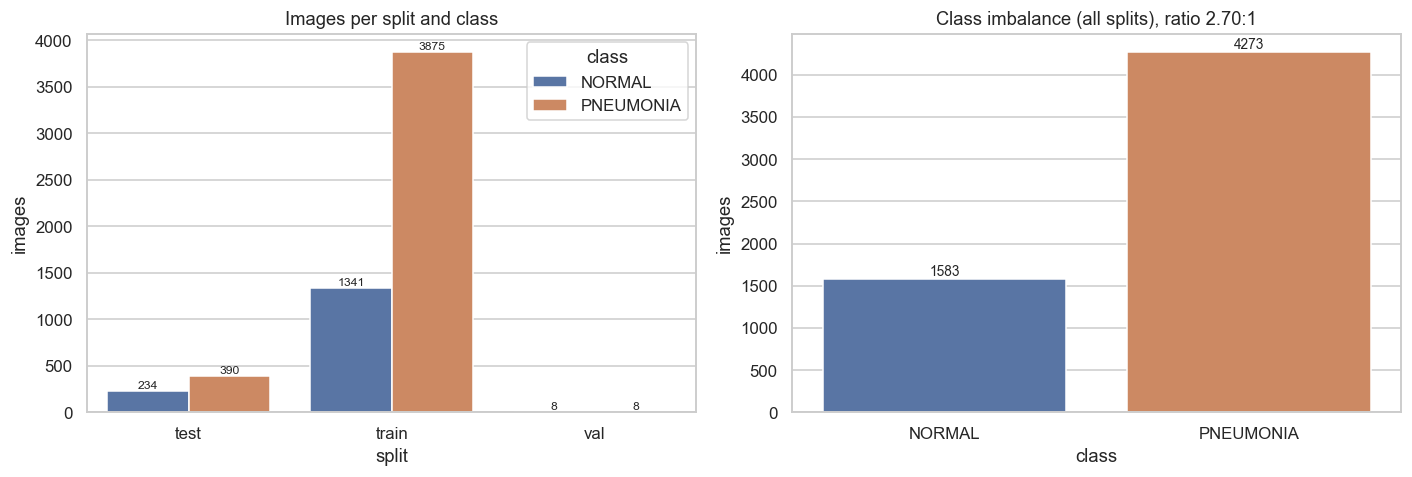

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

plot_df = df_all.groupby(["split", "class"]).size().reset_index(name="images")
sns.barplot(data=plot_df, x="split", y="images", hue="class", hue_order=CLASS_NAMES, ax=axes[0])
axes[0].set_title("Images per split and class")
for container in axes[0].containers:
    axes[0].bar_label(container, fontsize=8)

overall_df = overall.reset_index()
overall_df.columns = ["class", "images"]
sns.barplot(data=overall_df, x="class", y="images", hue="class", legend=False, ax=axes[1])
axes[1].set_title(f"Class imbalance (all splits), ratio {imbalance_ratio:.2f}:1")
for container in axes[1].containers:
    axes[1].bar_label(container, fontsize=9)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "class_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

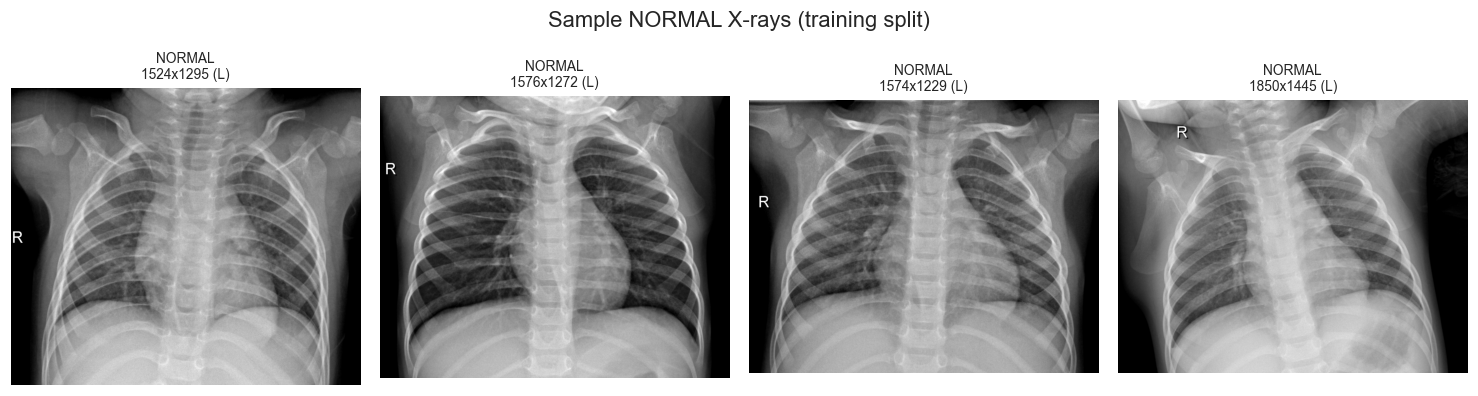

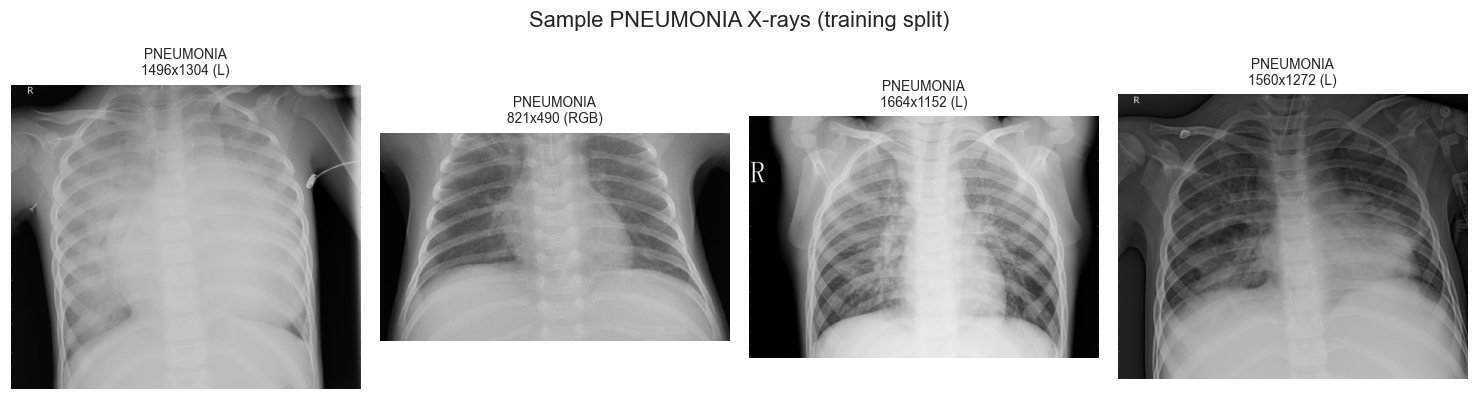

In [9]:
def show_samples(df, cls, n=4, seed=SEED):
    sample = df[df["class"] == cls].sample(n=min(n, (df["class"] == cls).sum()), random_state=seed)
    fig, axes = plt.subplots(1, len(sample), figsize=(3.4 * len(sample), 3.6), squeeze=False)
    for ax, (_, row) in zip(axes[0], sample.iterrows()):
        with Image.open(row["path"]) as im:
            size, mode = im.size, im.mode
            arr = np.asarray(im.convert("RGB"))
        ax.imshow(arr)
        ax.set_title(f"{cls}\n{size[0]}x{size[1]} ({mode})", fontsize=9)
        ax.axis("off")
    fig.suptitle(f"Sample {cls} X-rays (training split)", y=1.02)
    plt.tight_layout()
    return fig


train_only = df_all[df_all["split"] == "train"]
fig = show_samples(train_only, "NORMAL")
fig.savefig(RESULTS_DIR / "samples_normal.png", dpi=150, bbox_inches="tight")
plt.show()
fig = show_samples(train_only, "PNEUMONIA")
fig.savefig(RESULTS_DIR / "samples_pneumonia.png", dpi=150, bbox_inches="tight")
plt.show()

Image size statistics (sample of 400 images):


class              NORMAL    PNEUMONIA
width  count   200.000000   200.000000
       mean   1683.115000  1173.660000
       std     283.741498   273.848974
       min     976.000000   445.000000
       25%    1483.000000  1004.500000
       50%    1683.500000  1184.000000
       75%    1844.000000  1346.000000
       max    2721.000000  2050.000000
height count   200.000000   200.000000
       mean   1369.335000   797.355000
       std     320.265001   250.752975
       min     617.000000   177.000000
       25%    1139.000000   638.000000
       50%    1335.500000   776.000000
       75%    1509.250000   944.000000
       max    2625.000000  1560.000000

Colour modes in the sample: {'L': 386, 'RGB': 14} (grayscale images are converted to RGB later)


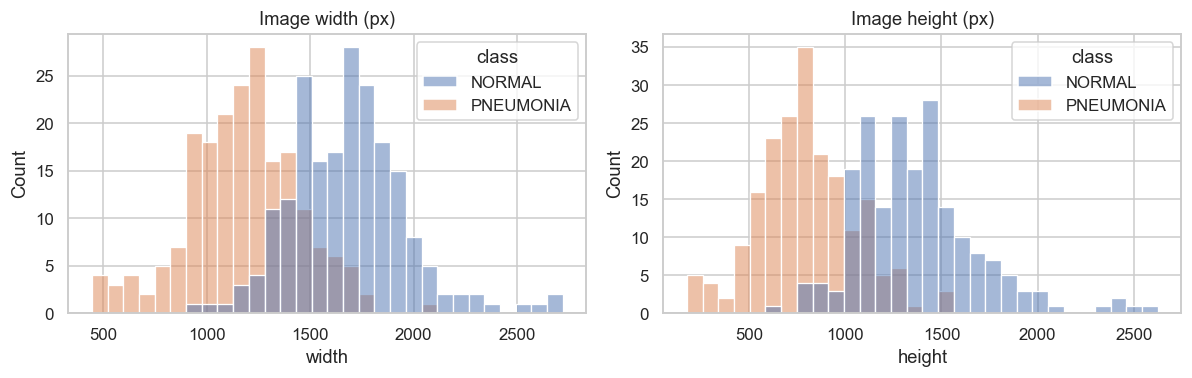

Original images vary a lot in size, so every image is resized to (224, 224) for the network.


In [10]:
# Image dimensions: read the header of a random sample (up to 200 images per class) - cheap and representative.
dim_rows = []
for cls in CLASS_NAMES:
    subset = df_all[df_all["class"] == cls]
    for _, row in subset.sample(n=min(200, len(subset)), random_state=SEED).iterrows():
        with Image.open(row["path"]) as im:
            dim_rows.append({"class": cls, "width": im.size[0], "height": im.size[1], "mode": im.mode})
dims = pd.DataFrame(dim_rows)

print(f"Image size statistics (sample of {len(dims)} images):")
display(dims.groupby("class")[["width", "height"]].describe().T)
print("Colour modes in the sample:", dims["mode"].value_counts().to_dict(), "(grayscale images are converted to RGB later)")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(data=dims, x="width", hue="class", bins=30, ax=axes[0])
sns.histplot(data=dims, x="height", hue="class", bins=30, ax=axes[1])
axes[0].set_title("Image width (px)")
axes[1].set_title("Image height (px)")
plt.tight_layout()
plt.show()
print("Original images vary a lot in size, so every image is resized to", IMG_SIZE, "for the network.")

## 5. Leakage-aware train / validation / test split

**Problem.** The original Kaggle `val/` folder has only 16 images - far too few to compare epochs or stop training reliably.

**Strategy used here**
1. Merge the original `train/` and `val/` images into one **development set**.
2. Remove exact duplicate images (SHA-1 of the file bytes) inside the development set, and remove any development image that is
   byte-identical to a test image.
3. Split the development set **80 : 20, stratified by class**, into *training* and *validation*.
   The split is additionally **grouped by patient** (parsed from the file names): X-rays of the same patient
   are never placed on both sides, which would otherwise make the validation score optimistic.
   If a file name cannot be parsed, that image forms its own group.
4. The original `test/` folder is **never touched**: not for training, validation, early stopping, learning-rate scheduling,
   class weights or any hyper-parameter choice. It is used exactly once, in the final evaluation.

In [11]:
t0 = time.time()
df_all["sha1"] = df_all["path"].map(file_hash)
print(f"Hashed {len(df_all)} images in {time.time() - t0:.1f}s")

dev_raw = df_all[df_all["split"].isin(["train", "val"])].copy()
test_df = df_all[df_all["split"] == "test"].copy().reset_index(drop=True)
if test_df.empty:
    raise RuntimeError("The test split is empty - check the dataset folder structure.")

# --- duplicate handling -------------------------------------------------------------------------------------
dup_within_dev = dev_raw.duplicated("sha1", keep="first")
dev = dev_raw[~dup_within_dev]
dup_with_test = dev["sha1"].isin(set(test_df["sha1"]))
dev = dev[~dup_with_test].copy()
print(f"Development images before cleaning : {len(dev_raw)}")
print(f"  exact duplicates inside dev set  : {int(dup_within_dev.sum())} removed")
print(f"  identical to a test image        : {int(dup_with_test.sum())} removed")
print(f"Development images after cleaning  : {len(dev)}")
print(f"Duplicate images inside the test set (kept, test is untouched): {int(test_df.duplicated('sha1').sum())}")

# --- stratified, patient-grouped 80:20 split ----------------------------------------------------------------
dev["group"] = [extract_group_id(f, c) for f, c in zip(dev["filename"], dev["class"])]
n_parsed = int((~dev["group"].str.contains(":file:")).sum())
print(f"\nPatient groups parsed from file names: {n_parsed}/{len(dev)} images, {dev['group'].nunique()} unique groups")

n_splits = int(round(1 / VAL_FRACTION))                      # 5 folds -> the first fold is ~20 %
sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
train_idx, val_idx = next(sgkf.split(dev, dev["label"], groups=dev["group"]))
train_df = dev.iloc[train_idx].reset_index(drop=True)
val_df = dev.iloc[val_idx].reset_index(drop=True)

# --- leakage checks -----------------------------------------------------------------------------------------
assert set(train_df["path"]).isdisjoint(val_df["path"]), "file overlap between train and validation"
assert set(train_df["path"]).isdisjoint(test_df["path"]), "file overlap between train and test"
assert set(val_df["path"]).isdisjoint(test_df["path"]), "file overlap between validation and test"
assert set(train_df["sha1"]).isdisjoint(val_df["sha1"]), "duplicate content between train and validation"
assert set(train_df["sha1"]).isdisjoint(test_df["sha1"]), "duplicate content between train and test"
assert set(val_df["sha1"]).isdisjoint(test_df["sha1"]), "duplicate content between validation and test"
assert set(train_df["group"]).isdisjoint(val_df["group"]), "patient overlap between train and validation"
print("\nLeakage checks passed: no shared files, no duplicate content, no shared patients between partitions.")

split_summary = pd.DataFrame({
    name: part["class"].value_counts().reindex(CLASS_NAMES, fill_value=0)
    for name, part in [("train", train_df), ("validation", val_df), ("test (untouched)", test_df)]
}).T
split_summary["Total"] = split_summary.sum(axis=1)
split_summary["% PNEUMONIA"] = (split_summary["PNEUMONIA"] / split_summary["Total"] * 100).round(2)
print("\nFinal partitions:")
display(split_summary)
print(f"Validation share of the development set: {len(val_df) / len(dev) * 100:.1f}%")

# Save the exact file lists (relative paths) for reproducibility
split_record = pd.concat([
    train_df.assign(partition="train"), val_df.assign(partition="validation"), test_df.assign(partition="test"),
])[["partition", "class", "label", "filename", "path", "sha1"]].copy()
split_record["path"] = [Path(p).relative_to(DATASET_ROOT).as_posix() for p in split_record["path"]]
split_record.to_csv(RESULTS_DIR / "data_splits.csv", index=False)
print("Saved split lists to", RESULTS_DIR / "data_splits.csv")

Hashed 5856 images in 3.0s
Development images before cleaning : 5232
  exact duplicates inside dev set  : 26 removed
  identical to a test image        : 0 removed
Development images after cleaning  : 5206
Duplicate images inside the test set (kept, test is untouched): 6

Patient groups parsed from file names: 5206/5206 images, 2650 unique groups

Leakage checks passed: no shared files, no duplicate content, no shared patients between partitions.

Final partitions:


class,NORMAL,PNEUMONIA,Total,% PNEUMONIA
train,1068,3100,4168,74.38
validation,280,758,1038,73.03
test (untouched),234,390,624,62.50


Validation share of the development set: 19.9%
Saved split lists to C:\Users\Vibha Poojary\Downloads\Pneumonia_Detection\Pneumonia_Detection\results\data_splits.csv


## 6. Shared module `inference_utils.py`

Everything that must behave **identically** in training, evaluation, Grad-CAM and the future Streamlit app is defined once
and written to `inference_utils.py` in the project root (this cell uses the `%%writefile` magic):

* constants: image size, class names and label mapping, layer names
* serializable custom layers: `DenseNetPreprocess`, `ChannelAttention`, `SpatialAttention`, `CBAM`
* `build_model()` - the DenseNet121 + CBAM architecture
* `preprocess_image_bytes()` / `load_image_tf()` - decode, RGB conversion, resize to 224x224
* `make_gradcam_heatmap()` - Grad-CAM that works with the nested DenseNet121
* `predict_xray()` - single-image prediction

**Model contract** (documented for the Streamlit app): input `float32 (batch, 224, 224, 3)`, RGB, **raw pixel values 0-255**;
output `float32 (batch, 1)` = sigmoid probability of `PNEUMONIA` (`0 = NORMAL`, `1 = PNEUMONIA`).
DenseNet normalisation is a layer *inside* the model, so training, evaluation and prediction cannot drift apart.

The components are explained in detail in the sections where they are used.

In [12]:
%%writefile inference_utils.py
"""Reusable code for the Pneumonia Detection project (DenseNet121 + CBAM).

This module is the single source of truth for everything that must behave
identically in training, evaluation, Grad-CAM and the future Streamlit app:

* constants (image size, class names, layer names)
* serializable custom Keras layers (DenseNetPreprocess, ChannelAttention,
  SpatialAttention, CBAM)
* the model builder
* image preprocessing (bytes / path -> uint8 224x224x3 tensor)
* Grad-CAM
* single-image prediction (predict_xray)

Model contract
--------------
Input  : float32 tensor (batch, 224, 224, 3), RGB, raw pixel values 0..255.
         DenseNet preprocessing is part of the model, so callers must NOT
         normalise images themselves.
Output : float32 tensor (batch, 1) = sigmoid probability of PNEUMONIA.
         Label mapping: 0 = NORMAL, 1 = PNEUMONIA.

Research prototype only - not a medical device.
"""
from __future__ import annotations

from pathlib import Path

import numpy as np
import tensorflow as tf
from tensorflow import keras

# --------------------------------------------------------------------------- #
# Constants
# --------------------------------------------------------------------------- #
IMG_SIZE = (224, 224)
INPUT_SHAPE = (224, 224, 3)
CLASS_NAMES = ["NORMAL", "PNEUMONIA"]
CLASS_TO_INDEX = {"NORMAL": 0, "PNEUMONIA": 1}
INDEX_TO_CLASS = {0: "NORMAL", 1: "PNEUMONIA"}
DECISION_THRESHOLD = 0.5

PACKAGE = "pneumonia"
BACKBONE_NAME = "densenet121"
PREPROCESS_LAYER_NAME = "densenet_preprocess"
HEAD_LAYER_NAMES = ("cbam", "gap", "head_dropout", "classifier")

DEFAULT_MODEL_PATH = Path(__file__).resolve().parent / "saved_models" / "best_pneumonia_model.keras"

# DenseNet121 in keras.applications uses "torch" preprocessing:
# scale to [0, 1], then subtract the ImageNet mean and divide by the ImageNet std.
_IMAGENET_MEAN = (0.485, 0.456, 0.406)
_IMAGENET_STD = (0.229, 0.224, 0.225)


# --------------------------------------------------------------------------- #
# Custom, serializable layers
# --------------------------------------------------------------------------- #
@keras.saving.register_keras_serializable(package=PACKAGE)
class DenseNetPreprocess(keras.layers.Layer):
    """ImageNet 'torch-mode' preprocessing used by DenseNet121 (inside the model)."""

    def call(self, inputs):
        x = tf.cast(inputs, tf.float32) / 255.0
        mean = tf.constant(_IMAGENET_MEAN, dtype=tf.float32)
        std = tf.constant(_IMAGENET_STD, dtype=tf.float32)
        return (x - mean) / std


@keras.saving.register_keras_serializable(package=PACKAGE)
class ChannelAttention(keras.layers.Layer):
    """CBAM channel attention: "what" to focus on.

    A shared two-layer MLP is applied to the global-average-pooled and the
    global-max-pooled descriptors; the sum goes through a sigmoid and rescales
    every channel of the input.
    """

    def __init__(self, reduction_ratio=16, **kwargs):
        super().__init__(**kwargs)
        self.reduction_ratio = int(reduction_ratio)

    def build(self, input_shape):
        channels = int(input_shape[-1])
        hidden = max(channels // self.reduction_ratio, 1)
        self.mlp_hidden = keras.layers.Dense(hidden, activation="relu", name="mlp_hidden")
        self.mlp_out = keras.layers.Dense(channels, name="mlp_out")
        # Build sub-layers explicitly so their weights exist before a saved
        # model's weights are restored (required for reliable .keras loading).
        self.mlp_hidden.build((None, channels))
        self.mlp_out.build((None, hidden))
        super().build(input_shape)

    def call(self, inputs):
        avg_desc = tf.reduce_mean(inputs, axis=[1, 2])
        max_desc = tf.reduce_max(inputs, axis=[1, 2])
        avg_out = self.mlp_out(self.mlp_hidden(avg_desc))
        max_out = self.mlp_out(self.mlp_hidden(max_desc))
        scale = tf.nn.sigmoid(avg_out + max_out)
        return inputs * scale[:, tf.newaxis, tf.newaxis, :]

    def get_config(self):
        config = super().get_config()
        config.update({"reduction_ratio": self.reduction_ratio})
        return config


@keras.saving.register_keras_serializable(package=PACKAGE)
class SpatialAttention(keras.layers.Layer):
    """CBAM spatial attention: "where" to focus.

    Channel-wise average and max maps are concatenated and passed through a
    7x7 convolution with sigmoid activation to give a (H, W, 1) attention map.
    """

    def __init__(self, kernel_size=7, **kwargs):
        super().__init__(**kwargs)
        self.kernel_size = int(kernel_size)

    def build(self, input_shape):
        self.conv = keras.layers.Conv2D(
            1, self.kernel_size, padding="same", activation="sigmoid", name="spatial_conv"
        )
        self.conv.build(tuple(input_shape[:-1]) + (2,))
        super().build(input_shape)

    def call(self, inputs):
        avg_map = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        max_map = tf.reduce_max(inputs, axis=-1, keepdims=True)
        attention = self.conv(tf.concat([avg_map, max_map], axis=-1))
        return inputs * attention

    def get_config(self):
        config = super().get_config()
        config.update({"kernel_size": self.kernel_size})
        return config


@keras.saving.register_keras_serializable(package=PACKAGE)
class CBAM(keras.layers.Layer):
    """Convolutional Block Attention Module: channel attention, then spatial attention."""

    def __init__(self, reduction_ratio=16, kernel_size=7, **kwargs):
        super().__init__(**kwargs)
        self.reduction_ratio = int(reduction_ratio)
        self.kernel_size = int(kernel_size)

    def build(self, input_shape):
        self.channel_attention = ChannelAttention(self.reduction_ratio, name="channel_attention")
        self.spatial_attention = SpatialAttention(self.kernel_size, name="spatial_attention")
        self.channel_attention.build(input_shape)
        self.spatial_attention.build(input_shape)
        super().build(input_shape)

    def call(self, inputs):
        x = self.channel_attention(inputs)
        return self.spatial_attention(x)

    def get_config(self):
        config = super().get_config()
        config.update({"reduction_ratio": self.reduction_ratio, "kernel_size": self.kernel_size})
        return config


CUSTOM_OBJECTS = {
    f"{PACKAGE}>DenseNetPreprocess": DenseNetPreprocess,
    f"{PACKAGE}>ChannelAttention": ChannelAttention,
    f"{PACKAGE}>SpatialAttention": SpatialAttention,
    f"{PACKAGE}>CBAM": CBAM,
    "DenseNetPreprocess": DenseNetPreprocess,
    "ChannelAttention": ChannelAttention,
    "SpatialAttention": SpatialAttention,
    "CBAM": CBAM,
}


# --------------------------------------------------------------------------- #
# Model
# --------------------------------------------------------------------------- #
def build_model(weights="imagenet", dropout_rate=0.4, cbam_reduction=16, cbam_kernel=7):
    """DenseNet121 (ImageNet) -> CBAM -> GAP -> Dropout -> Dense(1, sigmoid)."""
    inputs = keras.Input(shape=INPUT_SHAPE, name="xray_input")
    x = DenseNetPreprocess(name=PREPROCESS_LAYER_NAME)(inputs)

    backbone = keras.applications.DenseNet121(
        include_top=False,
        weights=weights,
        input_shape=INPUT_SHAPE,
        name=BACKBONE_NAME,
    )
    x = backbone(x)
    x = CBAM(reduction_ratio=cbam_reduction, kernel_size=cbam_kernel, name="cbam")(x)
    x = keras.layers.GlobalAveragePooling2D(name="gap")(x)
    x = keras.layers.Dropout(dropout_rate, name="head_dropout")(x)
    outputs = keras.layers.Dense(1, activation="sigmoid", name="classifier")(x)
    return keras.Model(inputs, outputs, name="DenseNet121_CBAM")


def load_trained_model(model_path=DEFAULT_MODEL_PATH):
    """Load the saved .keras model (custom layers are registered by importing this module)."""
    model_path = Path(model_path)
    if not model_path.is_file():
        raise FileNotFoundError(f"Model file not found: {model_path}")
    return keras.models.load_model(str(model_path), custom_objects=CUSTOM_OBJECTS, compile=False)


# --------------------------------------------------------------------------- #
# Image preprocessing (shared by training pipeline, evaluation, Grad-CAM, app)
# --------------------------------------------------------------------------- #
def preprocess_image_bytes(raw_bytes):
    """Encoded image bytes (JPEG/PNG/...) -> uint8 tensor (224, 224, 3), RGB.

    Grayscale images are expanded to 3 channels, RGBA is reduced to RGB.
    The DenseNet normalisation is NOT applied here; it is part of the model.
    """
    image = tf.io.decode_image(raw_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE, method="bilinear", antialias=True)
    return tf.cast(tf.round(tf.clip_by_value(image, 0.0, 255.0)), tf.uint8)


def load_image_tf(path):
    """File path (str or string tensor) -> uint8 tensor (224, 224, 3)."""
    return preprocess_image_bytes(tf.io.read_file(path))


def load_image_array(image_path):
    """Convenience wrapper for eager code: path -> numpy uint8 (224, 224, 3)."""
    image_path = Path(image_path).expanduser()
    if not image_path.is_file():
        raise FileNotFoundError(f"Image not found: {image_path}")
    try:
        return preprocess_image_bytes(image_path.read_bytes()).numpy()
    except tf.errors.InvalidArgumentError as exc:
        raise ValueError(f"Could not decode '{image_path}' as an image.") from exc


# --------------------------------------------------------------------------- #
# Grad-CAM
# --------------------------------------------------------------------------- #
def make_gradcam_heatmap(model, image_batch, class_index=None):
    """Grad-CAM for the DenseNet121 + CBAM model.

    The nested DenseNet121 is NOT reached through the outer functional graph.
    Instead the forward pass is split by hand:

        conv_maps = backbone(preprocess(image))        # last DenseNet feature maps
        output    = head(conv_maps)                    # CBAM -> GAP -> Dropout -> Dense

    Gradients of the class score are taken w.r.t. ``conv_maps`` (the final
    spatial feature maps of the backbone, before CBAM and the classifier).

    Parameters
    ----------
    image_batch : float tensor/array (1, 224, 224, 3), raw 0..255 RGB values.
    class_index : None (= explain the predicted class), 0 (NORMAL) or 1 (PNEUMONIA).

    Returns
    -------
    heatmap (H, W) float32 in [0, 1], sigmoid probability of PNEUMONIA, info dict.
    """
    image_batch = tf.convert_to_tensor(image_batch, dtype=tf.float32)
    if image_batch.shape.rank != 4 or image_batch.shape[0] != 1:
        raise ValueError(f"Expected a batch of exactly one image, got shape {image_batch.shape}")

    preprocess = model.get_layer(PREPROCESS_LAYER_NAME)
    backbone = model.get_layer(BACKBONE_NAME)
    head_layers = [model.get_layer(name) for name in HEAD_LAYER_NAMES]

    conv_maps = backbone(preprocess(image_batch), training=False)

    # Probability and the class to explain (decided before the tape starts).
    probability = float(model(image_batch, training=False).numpy().reshape(-1)[0])
    target = int(probability >= DECISION_THRESHOLD) if class_index is None else int(class_index)

    with tf.GradientTape() as tape:
        tape.watch(conv_maps)
        h = conv_maps
        for layer in head_layers:
            if isinstance(layer, keras.layers.Dropout):
                h = layer(h, training=False)
            else:
                h = layer(h)
        prob_tensor = h[:, 0]
        score = prob_tensor if target == 1 else 1.0 - prob_tensor

    grads = tape.gradient(score, conv_maps)
    if grads is None:
        raise RuntimeError(
            "Grad-CAM gradients are None: the head is not connected to the backbone feature maps."
        )

    weights = tf.reduce_mean(grads, axis=(0, 1, 2))            # (channels,)
    cam = tf.reduce_sum(conv_maps[0] * weights, axis=-1)       # (H, W)
    cam = tf.nn.relu(cam)
    cam_max = float(tf.reduce_max(cam))
    cam = (cam / cam_max).numpy() if cam_max > 0 else np.zeros(cam.shape, dtype=np.float32)

    grads_np = grads.numpy()
    info = {
        "target_class": INDEX_TO_CLASS[target],
        "feature_map_shape": tuple(int(s) for s in conv_maps.shape[1:]),
        "grad_abs_mean": float(np.abs(grads_np).mean()),
        "grad_nonzero_fraction": float((grads_np != 0).mean()),
        "heatmap_is_empty": cam_max <= 0,
    }
    return cam.astype(np.float32), probability, info


def heatmap_to_rgb(cam, size=IMG_SIZE):
    """Upsample a low-resolution CAM to ``size`` and apply the 'jet' colormap."""
    import matplotlib

    cam_resized = tf.image.resize(np.asarray(cam, dtype=np.float32)[..., np.newaxis], size, method="bilinear")
    cam_resized = np.clip(cam_resized.numpy()[..., 0], 0.0, 1.0)
    colored = matplotlib.colormaps["jet"](cam_resized)[..., :3]
    return cam_resized, colored


def overlay_heatmap(image_uint8, cam, alpha=0.4):
    """Blend the colored heatmap over the (224, 224, 3) uint8 image; returns floats in [0, 1]."""
    _, colored = heatmap_to_rgb(cam, size=image_uint8.shape[:2])
    base = image_uint8.astype("float32") / 255.0
    return np.clip((1.0 - alpha) * base + alpha * colored, 0.0, 1.0)


# --------------------------------------------------------------------------- #
# Prediction (reusable from notebook and Streamlit)
# --------------------------------------------------------------------------- #
_MODEL_CACHE = {}


def get_model(model_path=DEFAULT_MODEL_PATH):
    """Load the model once and reuse it (handy for Streamlit with st.cache_resource)."""
    key = str(Path(model_path).resolve())
    if key not in _MODEL_CACHE:
        _MODEL_CACHE[key] = load_trained_model(model_path)
    return _MODEL_CACHE[key]


def predict_image_bytes(model, raw_bytes, threshold=DECISION_THRESHOLD):
    """Predict from encoded image bytes (e.g. an uploaded file in Streamlit)."""
    image = preprocess_image_bytes(raw_bytes)
    batch = tf.cast(image, tf.float32)[tf.newaxis, ...]
    probability = float(model(batch, training=False).numpy().reshape(-1)[0])
    label_index = int(probability >= threshold)
    return {
        "label": CLASS_NAMES[label_index],
        "label_index": label_index,
        "sigmoid_output": probability,
        "confidence": probability if label_index == 1 else 1.0 - probability,
        "threshold": float(threshold),
        "image": image.numpy(),
    }


def predict_xray(image_path, model=None, threshold=DECISION_THRESHOLD, show=True, model_path=DEFAULT_MODEL_PATH):
    """Predict NORMAL / PNEUMONIA for one chest X-ray image file.

    Uses exactly the same decoding / RGB conversion / resizing as the training
    pipeline; DenseNet normalisation happens inside the model.
    """
    image_path = Path(image_path).expanduser()
    if not image_path.is_file():
        raise FileNotFoundError(f"Image not found: {image_path}")
    if model is None:
        model = get_model(model_path)
    try:
        result = predict_image_bytes(model, image_path.read_bytes(), threshold=threshold)
    except tf.errors.InvalidArgumentError as exc:
        raise ValueError(f"Could not decode '{image_path}' as an image.") from exc

    image = result.pop("image")
    result["image_path"] = str(image_path)

    if show:
        import matplotlib.pyplot as plt

        fig, ax = plt.subplots(figsize=(4.5, 4.8))
        ax.imshow(image)
        ax.axis("off")
        ax.set_title(
            f"Prediction: {result['label']}\n"
            f"sigmoid (P-PNEUMONIA) = {result['sigmoid_output']:.4f}  |  threshold = {threshold}",
            fontsize=10,
        )
        plt.tight_layout()
        plt.show()
        print("Research prototype only - not a medical diagnosis.")
    return result

Overwriting inference_utils.py


In [14]:
import importlib

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import inference_utils
importlib.reload(inference_utils)          # pick up edits if the module was written again
from inference_utils import (
    CLASS_NAMES as MODULE_CLASS_NAMES, IMG_SIZE as MODULE_IMG_SIZE,
    BACKBONE_NAME, PREPROCESS_LAYER_NAME, HEAD_LAYER_NAMES, CUSTOM_OBJECTS,
    DenseNetPreprocess, ChannelAttention, SpatialAttention, CBAM,
    build_model, load_trained_model, load_image_tf, load_image_array,
    make_gradcam_heatmap, heatmap_to_rgb, overlay_heatmap, predict_xray, predict_image_bytes,
)

assert list(MODULE_CLASS_NAMES) == CLASS_NAMES and tuple(MODULE_IMG_SIZE) == IMG_SIZE, \
    "Notebook configuration and inference_utils.py disagree - re-run the configuration cell."
print("inference_utils.py imported from", Path(inference_utils.__file__).resolve())
print("Custom layers registered:", [c.__name__ for c in (DenseNetPreprocess, ChannelAttention, SpatialAttention, CBAM)])

inference_utils.py imported from C:\Users\Vibha Poojary\Downloads\Pneumonia_Detection\Pneumonia_Detection\inference_utils.py
Custom layers registered: ['DenseNetPreprocess', 'ChannelAttention', 'SpatialAttention', 'CBAM']


## 7. `tf.data` pipelines, augmentation and class weights

**Preprocessing (identical for training, validation, test and single-image prediction)**

1. Read the file and decode it with `tf.io.decode_image(channels=3)` -> RGB (grayscale X-rays are replicated to 3 channels).
2. Resize to **224 x 224** (bilinear, anti-aliased) and keep the pixels as `uint8`.
3. Convert to `float32` in the range 0-255. The **DenseNet121 ImageNet normalisation** (divide by 255, subtract the ImageNet mean,
   divide by the ImageNet std - the mode `keras.applications.densenet` uses) is the first layer of the model, which is
   exactly what the pretrained weights expect.

**Pipeline efficiency:** `map(..., num_parallel_calls=AUTOTUNE)`, in-memory `cache()` of the decoded `uint8` images
(about 150 KB each) when RAM allows, shuffling for training only, batching and `prefetch`.

**Augmentation (training data only)** - small, anatomically plausible changes that imitate differences between X-ray machines and patient positioning:

| Transformation | Setting | Why |
|---|---|---|
| Rotation | about +/-11 degrees | patients are never positioned perfectly straight |
| Zoom | +/-10 % | different distances / field of view |
| Translation | +/-5 % | off-centre positioning |
| Contrast | +/-15 % | exposure and detector differences |

**Deliberately not used:** horizontal flips (would mirror the heart to the right side - an anatomically unrealistic
image), strong rotations/shears, aggressive crops (could remove lung regions) and colour jitter (images are grayscale).
Rotated/translated borders are filled with black (`fill_mode="constant"`) instead of reflected image content.
Validation and test images are **never** augmented.

In [15]:
AUTOTUNE = tf.data.AUTOTUNE

# Decide whether all decoded images fit comfortably in RAM (uint8: ~150 KB per image).
n_images_total = len(train_df) + len(val_df) + len(test_df)
bytes_needed = n_images_total * IMG_SIZE[0] * IMG_SIZE[1] * 3
try:
    import psutil
    USE_CACHE = bytes_needed < 0.35 * psutil.virtual_memory().available
except ImportError:
    USE_CACHE = True
print(f"Decoded images need about {bytes_needed / 1024**3:.2f} GB -> in-memory cache {'ENABLED' if USE_CACHE else 'DISABLED (not enough free RAM)'}")

# Augmentation: Keras preprocessing layers, applied to training batches only.
augmenter = keras.Sequential([
    keras.layers.RandomRotation(0.03, fill_mode="constant", fill_value=0.0, seed=SEED),   # 0.03 * 360 = ~10.8 degrees
    keras.layers.RandomZoom(0.10, fill_mode="constant", fill_value=0.0, seed=SEED),
    keras.layers.RandomTranslation(0.05, 0.05, fill_mode="constant", fill_value=0.0, seed=SEED),
    keras.layers.RandomContrast(0.15, seed=SEED),
], name="augmentation")


def augment_batch(images, labels):
    images = augmenter(images, training=True)
    return tf.clip_by_value(images, 0.0, 255.0), labels


def make_dataset(df, training, batch_size=BATCH_SIZE, cache=USE_CACHE):
    paths = df["path"].astype(str).tolist()
    labels = df["label"].to_numpy(dtype="float32").reshape(-1, 1)       # shape (N, 1) to match the (batch, 1) output
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    ds = ds.map(lambda p, y: (load_image_tf(p), y), num_parallel_calls=AUTOTUNE)
    if cache:
        ds = ds.cache()
    if training:
        ds = ds.shuffle(min(len(paths), 2048), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(batch_size)
    ds = ds.map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.map(augment_batch, num_parallel_calls=AUTOTUNE)         # augmentation ONLY for the training set
    return ds.prefetch(AUTOTUNE)


train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df, training=False)
test_ds = make_dataset(test_df, training=False)          # not shuffled: prediction order == test_df order

for name, ds in [("train", train_ds), ("validation", val_ds), ("test", test_ds)]:
    xb, yb = next(iter(ds))
    print(f"{name:10s} batch: images {xb.shape} {xb.dtype.name} range [{float(tf.reduce_min(xb)):.0f}, {float(tf.reduce_max(xb)):.0f}] | labels {yb.shape}")

Decoded images need about 0.82 GB -> in-memory cache ENABLED
train      batch: images (16, 224, 224, 3) float32 range [0, 255] | labels (16, 1)
validation batch: images (16, 224, 224, 3) float32 range [0, 255] | labels (16, 1)
test       batch: images (16, 224, 224, 3) float32 range [0, 253] | labels (16, 1)


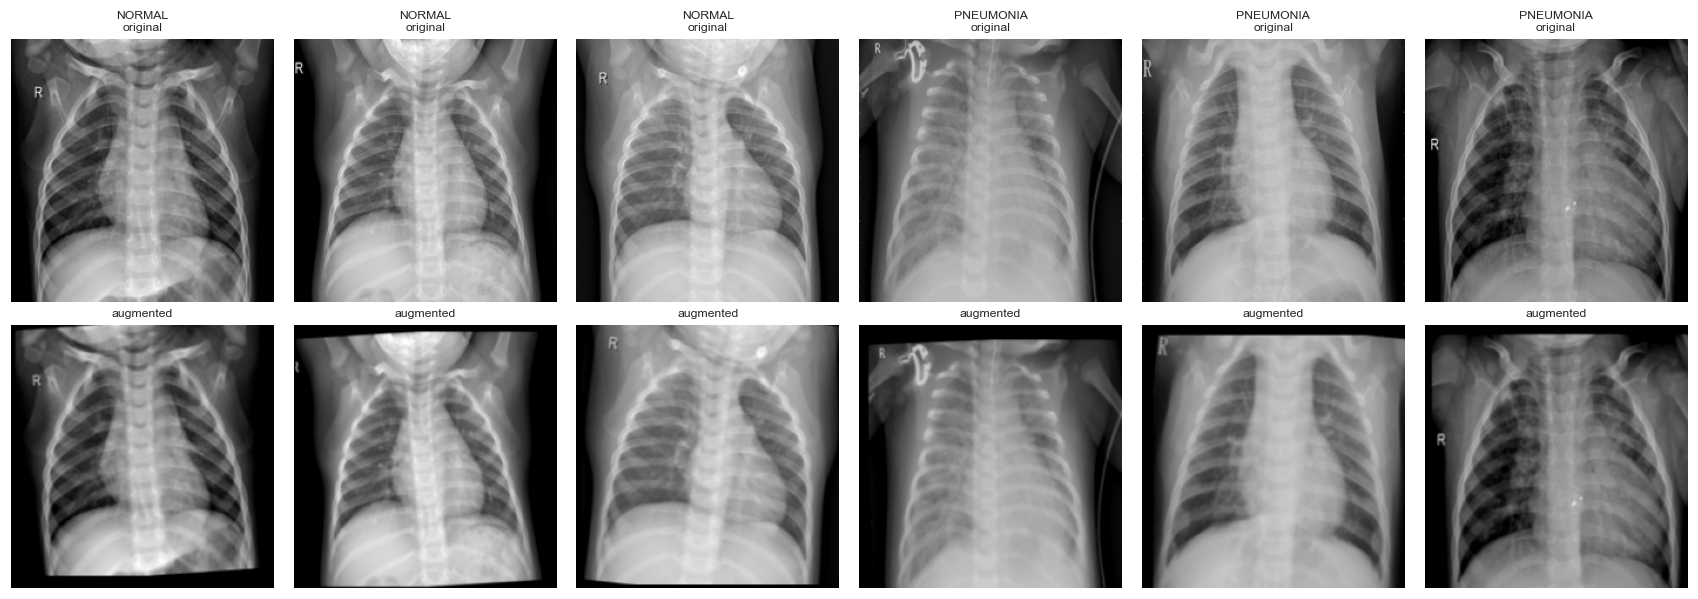

In [16]:
# Visual check of the augmentation: the same training images, original (top) vs augmented (bottom).
preview_rows = train_df.groupby("class").head(3).head(6)
originals = tf.stack([load_image_tf(p) for p in preview_rows["path"]])
originals_f = tf.cast(originals, tf.float32)
augmented = tf.clip_by_value(augmenter(originals_f, training=True), 0, 255)

fig, axes = plt.subplots(2, len(preview_rows), figsize=(2.6 * len(preview_rows), 5.6))
for i, (_, row) in enumerate(preview_rows.iterrows()):
    axes[0, i].imshow(originals[i].numpy())
    axes[0, i].set_title(f"{row['class']}\noriginal", fontsize=8)
    axes[1, i].imshow(tf.cast(augmented[i], tf.uint8).numpy())
    axes[1, i].set_title("augmented", fontsize=8)
    axes[0, i].axis("off"); axes[1, i].axis("off")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "augmentation_preview.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
# Class weights come from the TRAINING labels only (never from validation or test data).
weights_array = compute_class_weight(class_weight="balanced", classes=np.array([0, 1]), y=train_df["label"].to_numpy())
CLASS_WEIGHTS = {0: float(weights_array[0]), 1: float(weights_array[1])}

print("Training images per class:", train_df["class"].value_counts().reindex(CLASS_NAMES).to_dict())
print("Class weights (sklearn 'balanced'):")
for idx, w in CLASS_WEIGHTS.items():
    print(f"  {idx} = {CLASS_NAMES[idx]:10s} -> {w:.4f}")

Training images per class: {'NORMAL': 1068, 'PNEUMONIA': 3100}
Class weights (sklearn 'balanced'):
  0 = NORMAL     -> 1.9513
  1 = PNEUMONIA  -> 0.6723


## 8. Proposed architecture: DenseNet121 + CBAM

```
Input image (224 x 224 x 3, RGB, 0-255)
        |
        v
DenseNet preprocessing layer   (/255, ImageNet mean/std)
        |
        v
DenseNet121 backbone           (ImageNet weights, include_top=False)  ->  7 x 7 x 1024 feature maps
        |
        v
CBAM attention module
   |-- Channel attention  : which feature channels matter?   (avg-pool + max-pool -> shared MLP -> sigmoid -> rescale channels)
   |-- Spatial attention  : where in the image do they matter? (channel-avg + channel-max -> 7x7 conv -> sigmoid -> rescale locations)
        |
        v
Global Average Pooling  ->  Dropout (0.4)  ->  Dense(1, sigmoid)
        |
        v
P(PNEUMONIA)   ->   NORMAL / PNEUMONIA   (threshold 0.5)
```

**Role of the attention mechanism.** DenseNet121 produces 1024 feature channels on a 7 x 7 grid. Not all channels and not all
image locations are equally informative for pneumonia (e.g. lung opacities vs. text markers, shoulders or the heart border).
*Channel attention* learns a weight per channel; *spatial attention* learns a weight per location. Multiplying the feature maps
by these weights lets the classifier emphasise informative lung regions and suppress irrelevant ones, at a small cost
(about 0.13 M extra parameters at reduction ratio 16 - the exact number is printed below).

**Honest framing.** DenseNet121 and CBAM (Woo et al., 2018) are existing methods. This is a *proposed combination*; whether CBAM
actually helps cannot be claimed without an ablation (plain DenseNet121 vs. DenseNet121 + CBAM), which is listed as future work.

**Implementation notes**
* The CBAM layers are custom Keras layers decorated with `@keras.saving.register_keras_serializable`, implement `get_config()`
  and build their sub-layers explicitly, so the `.keras` file can be reloaded with `tf.keras.models.load_model()`.
* The DenseNet121 is kept as one nested layer named `densenet121`. This matters for Grad-CAM (section 13).

In [18]:
try:
    model = build_model(weights="imagenet", dropout_rate=DROPOUT_RATE,
                        cbam_reduction=CBAM_REDUCTION, cbam_kernel=CBAM_KERNEL)
except Exception as exc:
    print("Building the model failed. Loading the ImageNet weights needs an internet connection the first time")
    print("(they are cached in your user folder afterwards). Original error:")
    raise

backbone = model.get_layer(BACKBONE_NAME)
print("Model input shape :", model.input_shape)
print("Model output shape:", model.output_shape)
print("Backbone output   :", backbone.output.shape, "(final DenseNet121 feature maps fed into CBAM)")
print()
model.summary()

cbam_params = model.get_layer("cbam").count_params()
print(f"\nCBAM parameters       : {cbam_params:,}")
print(f"DenseNet121 parameters: {backbone.count_params():,}")
print(f"Total parameters      : {model.count_params():,}")


Model input shape : (None, 224, 224, 3)
Model output shape: (None, 1)
Backbone output   : (None, 7, 7, 1024) (final DenseNet121 feature maps fed into CBAM)



Model: "DenseNet121_CBAM"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ xray_input (InputLayer)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet_preprocess             │ (None, 224, 224, 3)    │             0 │
│ (DenseNetPreprocess)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ cbam (CBAM)                     │ (None, 7, 7, 1024)     │       132,259 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ head_dropout (Dropout)          │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classifier (Dense)              │ (None, 1)              │         1,025 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,170,788 (27.35 MB)

 Trainable params: 7,087,140 (27.04 MB)

 Non-trainable params: 83,648 (326.75 KB)


CBAM parameters       : 132,259
DenseNet121 parameters: 7,037,504
Total parameters      : 7,170,788


### 8.1 Pre-training self-tests

Before spending time on training, we verify the parts that most often fail:

1. our preprocessing layer equals `keras.applications.densenet.preprocess_input`,
2. the custom CBAM layers survive `get_config()` -> `from_config()`,
3. the model can be **saved and reloaded** from a `.keras` file with identical predictions,
4. **Grad-CAM** runs on the (still untrained) model and its gradients are **not `None`**.

If any test fails, the error appears here - not after hours of training.

In [19]:
rng = np.random.RandomState(SEED)
dummy = rng.randint(0, 256, size=(2, *IMG_SIZE, 3)).astype("float32")

# 1) preprocessing equivalence with the Keras reference implementation
ours = DenseNetPreprocess()(dummy).numpy()
reference = np.asarray(keras.applications.densenet.preprocess_input(dummy.copy()))
max_diff = float(np.abs(ours - reference).max())
print(f"[1] preprocessing max |difference| vs keras.applications.densenet.preprocess_input: {max_diff:.2e}")
assert max_diff < 1e-4, "DenseNet preprocessing mismatch"

# 2) layer config round trip
cbam_layer = model.get_layer("cbam")
clone = CBAM.from_config(cbam_layer.get_config())
assert clone.get_config() == cbam_layer.get_config()
print("[2] CBAM get_config()/from_config() round trip OK:", cbam_layer.get_config()["reduction_ratio"], cbam_layer.get_config()["kernel_size"])

# 3) save / reload round trip
with tempfile.TemporaryDirectory() as tmp:
    tmp_path = Path(tmp) / "selftest.keras"
    model.save(tmp_path)
    reloaded = tf.keras.models.load_model(str(tmp_path), compile=False)
    p_orig = model.predict(dummy, verbose=0)
    p_new = reloaded.predict(dummy, verbose=0)
    max_pred_diff = float(np.abs(p_orig - p_new).max())
    print(f"[3] save/load round trip OK, max |prediction difference| = {max_pred_diff:.2e}")
    assert max_pred_diff < 1e-4, "Reloaded model gives different predictions"
    # 4) Grad-CAM on the reloaded model (also proves Grad-CAM works after loading from disk)
    cam, prob, info = make_gradcam_heatmap(reloaded, dummy[:1])
    del reloaded

print("[4] Grad-CAM self-test:", info)
assert info["grad_nonzero_fraction"] > 0, "Grad-CAM gradients are all zero"
assert cam.shape == info["feature_map_shape"][:2]
print(f"    heatmap shape {cam.shape}, gradients not None, non-zero fraction {info['grad_nonzero_fraction']:.2f}")
print("\nAll self-tests passed.")

[1] preprocessing max |difference| vs keras.applications.densenet.preprocess_input: 0.00e+00
[2] CBAM get_config()/from_config() round trip OK: 16 7
[3] save/load round trip OK, max |prediction difference| = 0.00e+00
[4] Grad-CAM self-test: {'target_class': 'NORMAL', 'feature_map_shape': (7, 7, 1024), 'grad_abs_mean': 2.2842745238449425e-05, 'grad_nonzero_fraction': 1.0, 'heatmap_is_empty': False}
    heatmap shape (7, 7), gradients not None, non-zero fraction 1.00

All self-tests passed.


## 9. Stage 1 - feature extraction

The pretrained DenseNet121 backbone is **frozen**; only the CBAM module and the classification head are trained.
This lets the new randomly initialised layers adapt to the pretrained features without damaging them.

* Optimizer: Adam, learning rate `1e-4`; loss: binary cross-entropy
* Metrics tracked: accuracy, precision, recall (and AUC, used for model selection)
* Class weights from section 7 compensate for the PNEUMONIA : NORMAL imbalance
* Callbacks (all driven by the **validation** set only):
  * `EarlyStopping` - stops when validation AUC stops improving and restores the best weights
  * `ModelCheckpoint` - writes the best model to `saved_models/best_pneumonia_model.keras`
  * `ReduceLROnPlateau` - lowers the learning rate when validation AUC stalls

In [20]:
def make_metrics():
    """Fresh metric objects for every compile() call (accuracy, precision, recall, AUC)."""
    return [
        keras.metrics.BinaryAccuracy(name="accuracy"),
        keras.metrics.Precision(name="precision"),
        keras.metrics.Recall(name="recall"),
        keras.metrics.AUC(name="auc"),
    ]


def make_callbacks(patience, checkpoint_threshold=None):
    return [
        keras.callbacks.EarlyStopping(monitor=MONITOR, mode="max", patience=patience,
                                      restore_best_weights=True, verbose=1),
        keras.callbacks.ModelCheckpoint(filepath=str(BEST_MODEL_PATH), monitor=MONITOR, mode="max",
                                        save_best_only=True, initial_value_threshold=checkpoint_threshold, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor=MONITOR, mode="max", factor=0.3, patience=2,
                                          min_lr=1e-7, verbose=1),
    ]


def count_params(weights):
    return int(sum(np.prod(w.shape) for w in weights))

In [21]:
backbone = model.get_layer(BACKBONE_NAME)
backbone.trainable = False

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=STAGE1_LR),
    loss="binary_crossentropy",
    metrics=make_metrics(),
)
print(f"Stage 1 | trainable parameters: {count_params(model.trainable_weights):,} | "
      f"frozen: {count_params(model.non_trainable_weights):,}")

t0 = time.time()
history_stage1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=STAGE1_MAX_EPOCHS,
    class_weight=CLASS_WEIGHTS,
    callbacks=make_callbacks(STAGE1_PATIENCE),
    verbose=1,
)
stage1_minutes = (time.time() - t0) / 60
best_val_auc_stage1 = float(np.max(history_stage1.history[MONITOR]))
print(f"\nStage 1 finished: {len(history_stage1.history['loss'])} epochs in {stage1_minutes:.1f} min | best {MONITOR} = {best_val_auc_stage1:.4f}")
if not BEST_MODEL_PATH.is_file():
    raise RuntimeError("No checkpoint was written in stage 1 - check the training log above.")

Stage 1 | trainable parameters: 133,284 | frozen: 7,037,504
Epoch 1/15
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 465ms/step - accuracy: 0.4947 - auc: 0.7369 - loss: 0.6862 - precision: 0.9065 - recall: 0.2371
Epoch 1: val_auc improved from None to 0.97742, saving model to C:\Users\Vibha Poojary\Downloads\Pneumonia_Detection\Pneumonia_Detection\saved_models\best_pneumonia_model.keras
261/261 ━━━━━━━━━━━━━━━━━━━━ 166s 592ms/step - accuracy: 0.6437 - auc: 0.8404 - loss: 0.5592 - precision: 0.9519 - recall: 0.5487 - val_accuracy: 0.8690 - val_auc: 0.9774 - val_loss: 0.3517 - val_precision: 0.9937 - val_recall: 0.8259 - learning_rate: 1.0000e-04
Epoch 2/15
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 445ms/step - accuracy: 0.8972 - auc: 0.9690 - loss: 0.2631 - precision: 0.9729 - recall: 0.8587
Epoch 2: val_auc improved from 0.97742 to 0.98160, saving model to C:\Users\Vibha Poojary\Downloads\Pneumonia_Detection\Pneumonia_Detection\saved_models\best_pneumonia_model.keras
261/261 ━━━━━━━━━━━━━━━━━━━━ 145s 555ms/st

## 10. Stage 2 - fine-tuning

Now the **upper part of DenseNet121 (the last dense block, `conv5_*`) is unfrozen** so that high-level features can adapt to
X-ray images. The early layers keep their generic ImageNet filters (edges, textures).

* **BatchNormalization layers stay frozen**, so the pretrained running statistics are not disturbed by the small batches.
* A **much smaller learning rate (`1e-5`)** is used, and the model is **re-compiled** because the set of trainable layers changed.
* The checkpoint only overwrites the saved model if validation AUC **beats the best value from stage 1**, so the file
  `best_pneumonia_model.keras` always contains the best model seen on the validation set.
* Early stopping avoids unnecessary epochs.

In [23]:
backbone = model.get_layer(BACKBONE_NAME)
backbone.trainable = True

layer_names = [layer.name for layer in backbone.layers]
start_index = next((i for i, n in enumerate(layer_names) if n.startswith(FINETUNE_FROM_PREFIX)), int(len(layer_names) * 0.7))
for i, layer in enumerate(backbone.layers):
    layer.trainable = (i >= start_index) and not isinstance(layer, keras.layers.BatchNormalization)

n_unfrozen = sum(1 for layer in backbone.layers if layer.trainable)
print(f"Backbone layers: {len(backbone.layers)} | fine-tuning from layer #{start_index} ('{layer_names[start_index]}') "
      f"| trainable backbone layers (BatchNorm excluded): {n_unfrozen}")

model.compile(                                              # re-compile after changing `trainable`
    optimizer=keras.optimizers.Adam(learning_rate=STAGE2_LR),
    loss="binary_crossentropy",
    metrics=make_metrics(),
)
print(f"Stage 2 | trainable parameters: {count_params(model.trainable_weights):,} | "
      f"frozen: {count_params(model.non_trainable_weights):,}")

t0 = time.time()
history_stage2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=STAGE2_MAX_EPOCHS,
    class_weight=CLASS_WEIGHTS,
    callbacks=make_callbacks(STAGE2_PATIENCE, checkpoint_threshold=best_val_auc_stage1),
    verbose=1,
)
stage2_minutes = (time.time() - t0) / 60
best_val_auc_stage2 = float(np.max(history_stage2.history[MONITOR]))
print(f"\nStage 2 finished: {len(history_stage2.history['loss'])} epochs in {stage2_minutes:.1f} min | best {MONITOR} = {best_val_auc_stage2:.4f}")

if best_val_auc_stage2 > best_val_auc_stage1:
    SELECTED_STAGE = "stage 2 (fine-tuned)"
else:
    SELECTED_STAGE = "stage 1 (feature extraction) - fine-tuning did not improve validation AUC"
print("Selected model (by validation AUC):", SELECTED_STAGE)

Backbone layers: 427 | fine-tuning from layer #313 ('conv5_block1_0_bn') | trainable backbone layers (BatchNorm excluded): 81
Stage 2 | trainable parameters: 2,263,204 | frozen: 4,907,584
Epoch 1/15
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 495ms/step - accuracy: 0.9808 - auc: 0.9983 - loss: 0.0507 - precision: 0.9950 - recall: 0.9756
Epoch 1: val_auc improved from 0.98709 to 0.99353, saving model to C:\Users\Vibha Poojary\Downloads\Pneumonia_Detection\Pneumonia_Detection\saved_models\best_pneumonia_model.keras
261/261 ━━━━━━━━━━━━━━━━━━━━ 168s 611ms/step - accuracy: 0.9834 - auc: 0.9987 - loss: 0.0415 - precision: 0.9957 - recall: 0.9819 - val_accuracy: 0.9701 - val_auc: 0.9935 - val_loss: 0.1178 - val_precision: 0.9946 - val_recall: 0.9644 - learning_rate: 1.0000e-05
Epoch 2/15
261/261 ━━━━━━━━━━━━━━━━━━━━ 0s 460ms/step - accuracy: 0.9808 - auc: 0.9990 - loss: 0.0426 - precision: 0.9935 - recall: 0.9759
Epoch 2: val_auc did not improve from 0.99353
261/261 ━━━━━━━━━━━━━━━━━━━━ 148s 565ms/step 

## 11. Training curves

The curves below are drawn from the **actual Keras history** of both stages (the dashed line marks the start of fine-tuning).

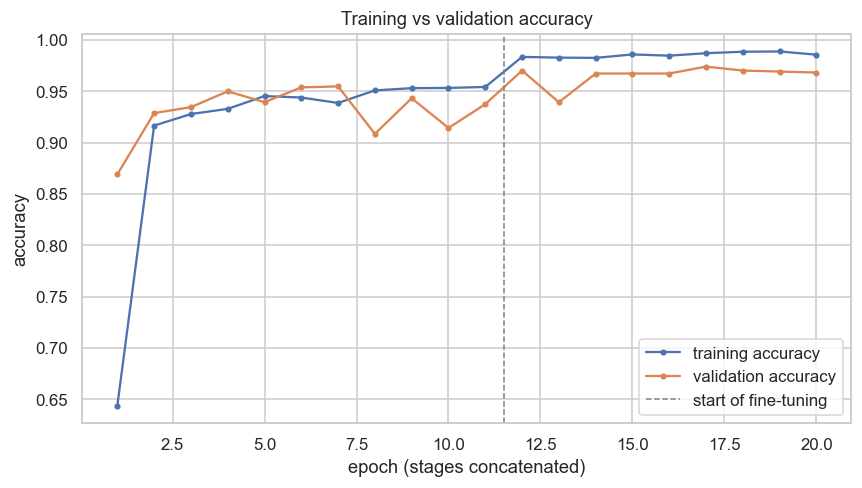

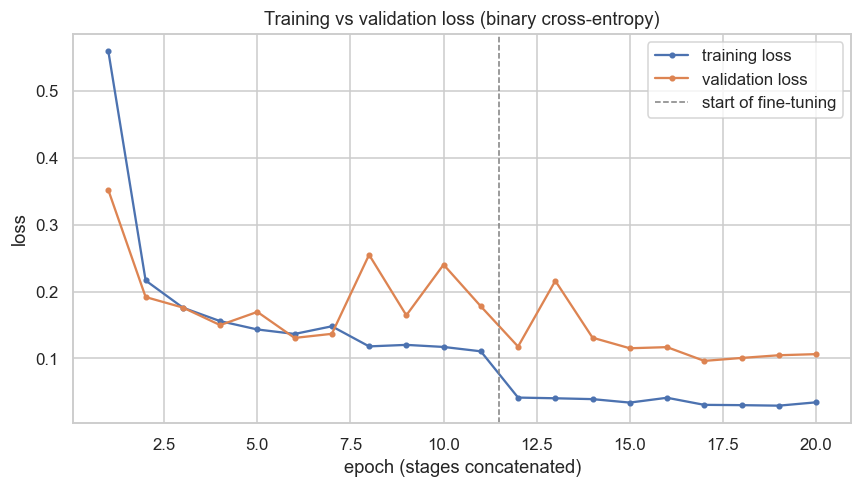

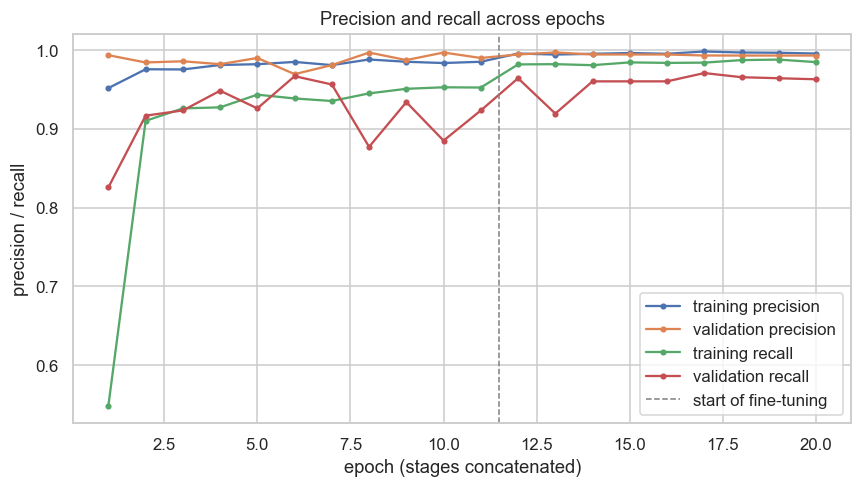

,accuracy,auc,loss,precision,recall,val_accuracy,val_auc,val_loss,val_precision,val_recall,learning_rate,stage
epoch,,,,,,,,,,,,
13,0.9827,0.9988,0.0405,0.9944,0.9823,0.9393,0.9905,0.2161,0.9971,0.9195,0.0,stage 2: fine-tuning
14,0.9825,0.9985,0.0392,0.9954,0.9810,0.9672,0.9929,0.1311,0.9945,0.9604,0.0,stage 2: fine-tuning
15,0.9858,0.9991,0.0340,0.9964,0.9845,0.9672,0.9935,0.1153,0.9945,0.9604,0.0,stage 2: fine-tuning
16,0.9846,0.9986,0.0412,0.9954,0.9839,0.9672,0.9935,0.1170,0.9945,0.9604,0.0,stage 2: fine-tuning
17,0.9870,0.9991,0.0306,0.9984,0.9842,0.9740,0.9924,0.0964,0.9933,0.9710,0.0,stage 2: fine-tuning
18,0.9885,0.9994,0.0302,0.9971,0.9874,0.9701,0.9935,0.1008,0.9932,0.9657,0.0,stage 2: fine-tuning
19,0.9887,0.9993,0.0294,0.9967,0.9881,0.9692,0.9935,0.1048,0.9932,0.9644,0.0,stage 2: fine-tuning
20,0.9856,0.9993,0.0344,0.9958,0.9848,0.9682,0.9935,0.1065,0.9932,0.9631,0.0,stage 2: fine-tuning


In [24]:
h1 = pd.DataFrame(history_stage1.history).assign(stage="stage 1: feature extraction")
h2 = pd.DataFrame(history_stage2.history).assign(stage="stage 2: fine-tuning")
history_df = pd.concat([h1, h2], ignore_index=True)
history_df.index = np.arange(1, len(history_df) + 1)
history_df.index.name = "epoch"
boundary = len(h1) + 0.5


def plot_curves(pairs, title, filename, ylabel):
    fig, ax = plt.subplots(figsize=(8, 4.6))
    for column, label in pairs:
        ax.plot(history_df.index, history_df[column], marker="o", ms=3, label=label)
    ax.axvline(boundary, color="gray", linestyle="--", linewidth=1, label="start of fine-tuning")
    ax.set_xlabel("epoch (stages concatenated)")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.legend()
    plt.tight_layout()
    fig.savefig(RESULTS_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()


plot_curves([("accuracy", "training accuracy"), ("val_accuracy", "validation accuracy")],
            "Training vs validation accuracy", "training_accuracy.png", "accuracy")
plot_curves([("loss", "training loss"), ("val_loss", "validation loss")],
            "Training vs validation loss (binary cross-entropy)", "training_loss.png", "loss")
plot_curves([("precision", "training precision"), ("val_precision", "validation precision"),
             ("recall", "training recall"), ("val_recall", "validation recall")],
            "Precision and recall across epochs", "training_precision_recall.png", "precision / recall")

display(history_df.round(4).tail(8))

## 12. Evaluation on the untouched test set

Only now is the test set used - **once**, with the final selected model. We reload the saved file from disk (the same file the
Streamlit app will use), so the evaluated model is exactly the saved model.

Metrics (all from `sklearn.metrics`, decision threshold 0.5, positive class = PNEUMONIA):
accuracy, precision, recall (= sensitivity), specificity, F1-score, ROC-AUC and average precision.

**Reading the results responsibly.** For a screening-type task a **false negative** (a pneumonia case predicted as NORMAL) is the
costly error. The test accuracy alone says nothing about clinical reliability: the test set comes from one source (paediatric
patients from a single institution), is relatively small and imbalanced, and the model was not validated on external data.

In [25]:
final_model = load_trained_model(BEST_MODEL_PATH)            # best checkpoint saved on disk
print("Evaluating:", BEST_MODEL_PATH.name, "| selected:", SELECTED_STAGE)

y_prob = final_model.predict(test_ds, verbose=0).reshape(-1)
y_true = test_df["label"].to_numpy()
assert len(y_prob) == len(y_true), "prediction count does not match the number of test images"
y_pred = (y_prob >= DECISION_THRESHOLD).astype(int)

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
tn, fp, fn, tp = (int(v) for v in cm.ravel())

test_metrics = {
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "precision": float(precision_score(y_true, y_pred, zero_division=0)),
    "recall_sensitivity": float(recall_score(y_true, y_pred, zero_division=0)),
    "specificity": float(tn / (tn + fp)) if (tn + fp) else float("nan"),
    "f1_score": float(f1_score(y_true, y_pred, zero_division=0)),
    "roc_auc": float(roc_auc_score(y_true, y_prob)),
    "average_precision": float(average_precision_score(y_true, y_prob)),
    "true_positives": tp, "true_negatives": tn, "false_positives": fp, "false_negatives": fn,
    "threshold": DECISION_THRESHOLD, "n_test_images": int(len(y_true)),
}

print(pd.Series(test_metrics).to_string())
print(f"\nTrue Positives  (pneumonia found)       : {tp}")
print(f"True Negatives  (normal recognised)     : {tn}")
print(f"False Positives (normal flagged)        : {fp}")
print(f"False Negatives (pneumonia MISSED)      : {fn}   <-- most important error type")

report_text = classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0)
print("\nClassification report:\n" + report_text)
(RESULTS_DIR / "classification_report.txt").write_text(
    "Classification report (test set, threshold {})\n\n{}\n".format(DECISION_THRESHOLD, report_text), encoding="utf-8")

Evaluating: best_pneumonia_model.keras | selected: stage 2 (fine-tuned)
accuracy                0.895833
precision               0.865169
recall_sensitivity      0.987179
specificity             0.743590
f1_score                0.922156
roc_auc                 0.967702
average_precision       0.975925
true_positives        385.000000
true_negatives        174.000000
false_positives        60.000000
false_negatives         5.000000
threshold               0.500000
n_test_images         624.000000

True Positives  (pneumonia found)       : 385
True Negatives  (normal recognised)     : 174
False Positives (normal flagged)        : 60
False Negatives (pneumonia MISSED)      : 5   <-- most important error type

Classification report:
              precision    recall  f1-score   support

      NORMAL     0.9721    0.7436    0.8426       234
   PNEUMONIA     0.8652    0.9872    0.9222       390

    accuracy                         0.8958       624
   macro avg     0.9186    0.8654    0.8824

376

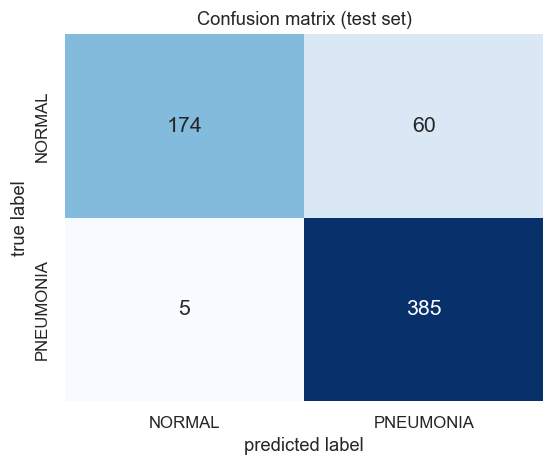

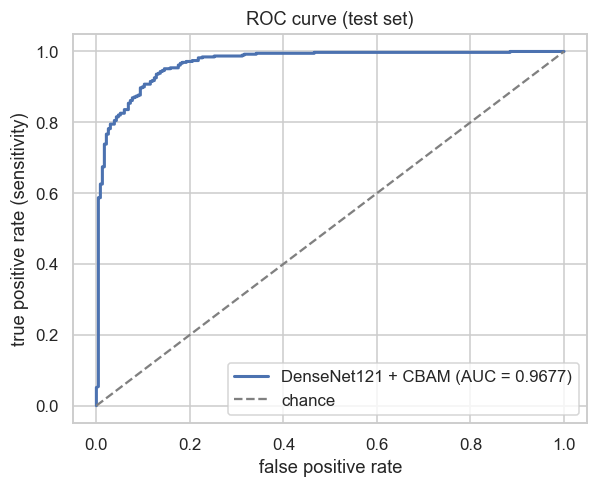

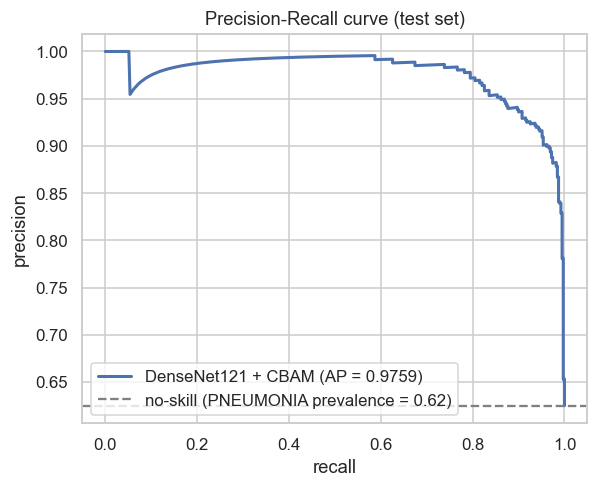

In [26]:
# Confusion matrix
fig, ax = plt.subplots(figsize=(5.2, 4.4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, annot_kws={"size": 14})
ax.set_xlabel("predicted label")
ax.set_ylabel("true label")
ax.set_title("Confusion matrix (test set)")
plt.tight_layout()
fig.savefig(RESULTS_DIR / "confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

# ROC curve
fpr, tpr, _ = roc_curve(y_true, y_prob)
fig, ax = plt.subplots(figsize=(5.6, 4.6))
ax.plot(fpr, tpr, linewidth=2, label=f"DenseNet121 + CBAM (AUC = {test_metrics['roc_auc']:.4f})")
ax.plot([0, 1], [0, 1], "--", color="gray", label="chance")
ax.set_xlabel("false positive rate")
ax.set_ylabel("true positive rate (sensitivity)")
ax.set_title("ROC curve (test set)")
ax.legend(loc="lower right")
plt.tight_layout()
fig.savefig(RESULTS_DIR / "roc_curve.png", dpi=150, bbox_inches="tight")
plt.show()

# Precision-Recall curve
prec, rec, _ = precision_recall_curve(y_true, y_prob)
prevalence = float(np.mean(y_true))
fig, ax = plt.subplots(figsize=(5.6, 4.6))
ax.plot(rec, prec, linewidth=2, label=f"DenseNet121 + CBAM (AP = {test_metrics['average_precision']:.4f})")
ax.axhline(prevalence, linestyle="--", color="gray", label=f"no-skill (PNEUMONIA prevalence = {prevalence:.2f})")
ax.set_xlabel("recall")
ax.set_ylabel("precision")
ax.set_title("Precision-Recall curve (test set)")
ax.legend(loc="lower left")
plt.tight_layout()
fig.savefig(RESULTS_DIR / "precision_recall_curve.png", dpi=150, bbox_inches="tight")
plt.show()

False negatives (missed pneumonia): 5 of 390 pneumonia images -> miss rate 1.3%
False positives (normal flagged)  : 60 of 234 normal images


,filename,prob_pneumonia
436,person1643_virus_2843.jpeg,0.339227
567,person79_virus_148.jpeg,0.304177
404,person15_virus_46.jpeg,0.149575
473,person16_virus_47.jpeg,0.032743
391,person154_bacteria_728.jpeg,0.000187


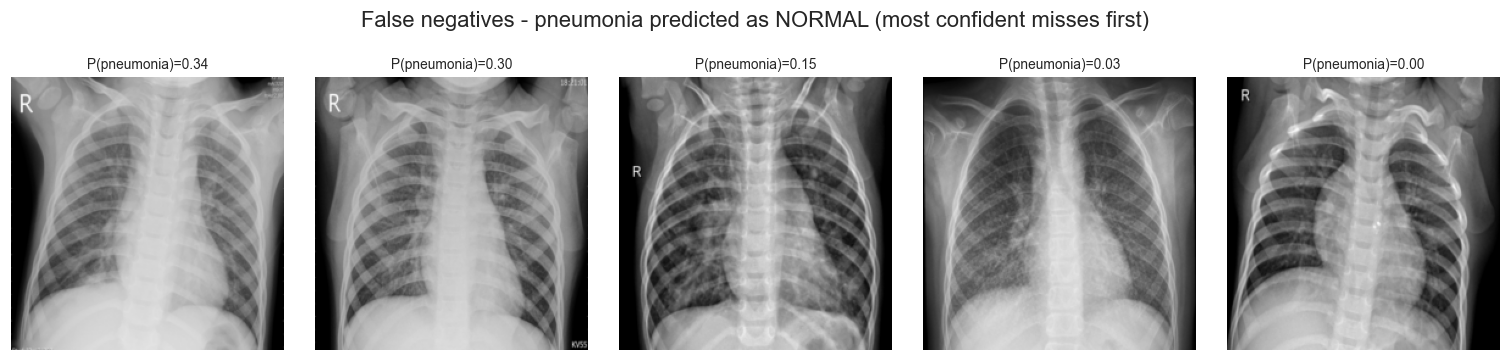

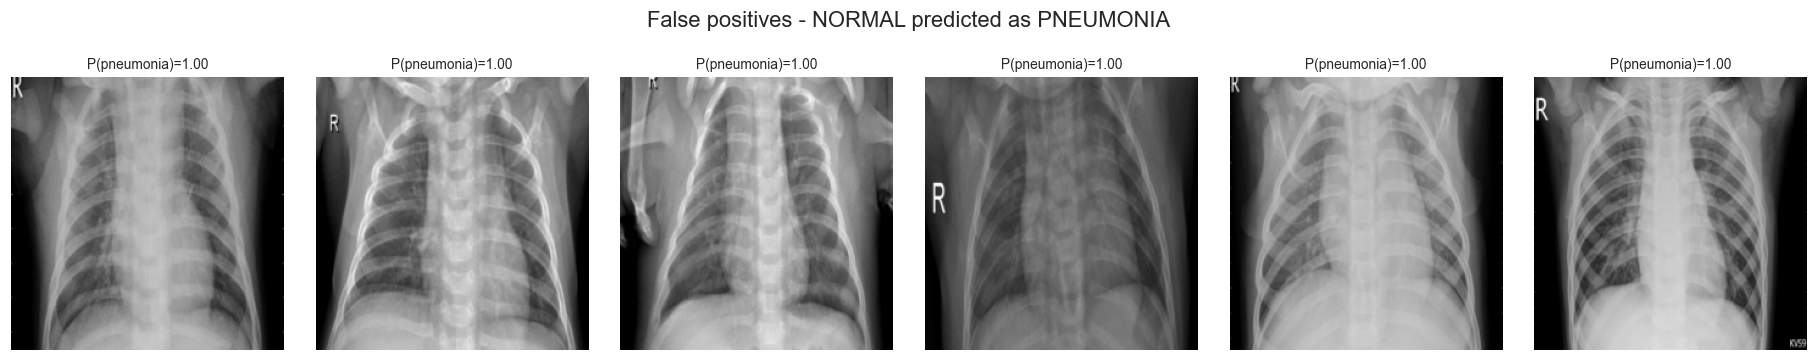

In [27]:
# Error analysis: which pneumonia cases were missed?
results_df = test_df[["path", "filename", "class", "label"]].copy()
results_df["prob_pneumonia"] = y_prob
results_df["pred"] = y_pred

fn_df = results_df[(results_df["label"] == 1) & (results_df["pred"] == 0)].sort_values("prob_pneumonia", ascending=False)
fp_df = results_df[(results_df["label"] == 0) & (results_df["pred"] == 1)].sort_values("prob_pneumonia", ascending=False)
print(f"False negatives (missed pneumonia): {len(fn_df)} of {int((y_true == 1).sum())} pneumonia images "
      f"-> miss rate {len(fn_df) / max(int((y_true == 1).sum()), 1):.1%}")
print(f"False positives (normal flagged)  : {len(fp_df)} of {int((y_true == 0).sum())} normal images")
display(fn_df[["filename", "prob_pneumonia"]].head(10))


def show_errors(err_df, title, n=6):
    err_df = err_df.head(n)
    if err_df.empty:
        print(f"No {title.lower()} to display.")
        return
    fig, axes = plt.subplots(1, len(err_df), figsize=(2.8 * len(err_df), 3.2), squeeze=False)
    for ax, (_, row) in zip(axes[0], err_df.iterrows()):
        ax.imshow(load_image_array(row["path"]))
        ax.set_title(f"P(pneumonia)={row['prob_pneumonia']:.2f}", fontsize=9)
        ax.axis("off")
    fig.suptitle(title, y=1.02)
    plt.tight_layout()
    plt.show()


show_errors(fn_df, "False negatives - pneumonia predicted as NORMAL (most confident misses first)")
show_errors(fp_df, "False positives - NORMAL predicted as PNEUMONIA")

## 13. Grad-CAM explainability

**Why the old approach fails.** With a nested model (`DenseNet121` used as a layer inside the outer model), the backbone's inner
layers are **not part of the outer model's graph**. Asking for `outer_model.get_layer("conv5_block16_concat").output`
or building `Model(outer.input, [densenet_layer.output, outer.output])` raises graph-disconnected errors or returns `None` gradients.

**The approach used here.** We split the forward pass by hand and let `tf.GradientTape` see the connection explicitly:

```
conv_maps = densenet121( preprocess(image) )            # final 7 x 7 x 1024 backbone feature maps (outside the tape)
with tf.GradientTape() as tape:
    tape.watch(conv_maps)                                # we differentiate w.r.t. these feature maps
    output = dense( dropout( gap( cbam(conv_maps) ) ) )  # CBAM + classification head
grads = tape.gradient(class_score, conv_maps)           # (1, 7, 7, 1024)
weights = mean(grads over height and width)             # importance of each feature channel
cam = ReLU( sum_k weights[k] * conv_maps[..., k] )      # coarse 7 x 7 localisation map, scaled to [0, 1]
```

The gradients are taken with respect to the **final DenseNet121 feature maps before CBAM and the head**, and the code raises
an error if they are `None`. By default the explained class is the *predicted* class (for a sigmoid output the score is
`p` for PNEUMONIA and `1 - p` for NORMAL). The 7 x 7 map is upsampled to 224 x 224 and overlaid with the `jet` colour map
(red = strongest evidence).

**Interpret with care:** Grad-CAM shows where the network looked, not proof that it used the right clinical evidence.
It can highlight borders, text markers or devices (shortcut learning) and is a coarse tool.

In [28]:
# Gradient sanity check on one real test image with the FINAL model
check_row = test_df[test_df["class"] == "PNEUMONIA"].iloc[0]
check_img = load_image_array(check_row["path"])
cam, prob, info = make_gradcam_heatmap(final_model, check_img.astype("float32")[np.newaxis, ...])

print("Grad-CAM check on:", check_row["filename"])
for key, value in info.items():
    print(f"  {key}: {value}")
assert info["grad_nonzero_fraction"] > 0, "gradients are all zero"
assert not info["heatmap_is_empty"], "heatmap is empty (all ReLU outputs are zero)"
print(f"Gradients are not None, heatmap shape {cam.shape}, P(pneumonia) = {prob:.4f}  -> Grad-CAM works.")

Grad-CAM check on: person100_bacteria_475.jpeg
  target_class: PNEUMONIA
  feature_map_shape: (7, 7, 1024)
  grad_abs_mean: 1.7722873053571675e-06
  grad_nonzero_fraction: 1.0
  heatmap_is_empty: False
Gradients are not None, heatmap shape (7, 7), P(pneumonia) = 0.9988  -> Grad-CAM works.


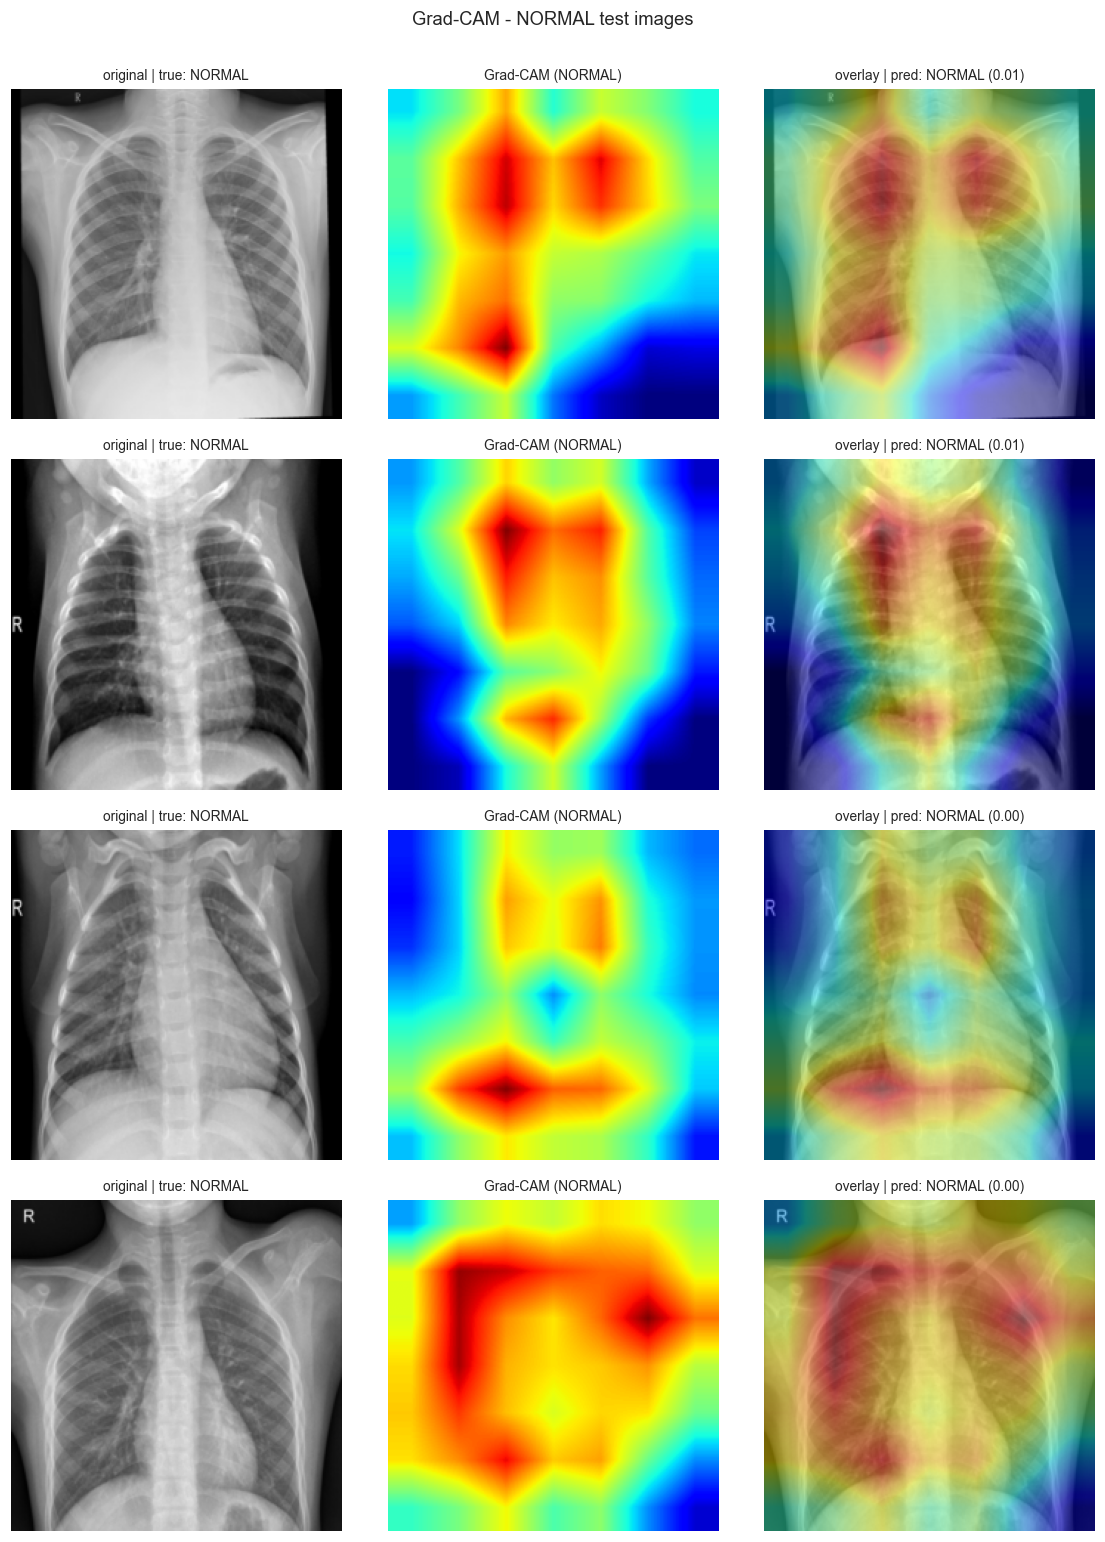

Saved C:\Users\Vibha Poojary\Downloads\Pneumonia_Detection\Pneumonia_Detection\results\gradcam\gradcam_normal.png  (4/4 images)


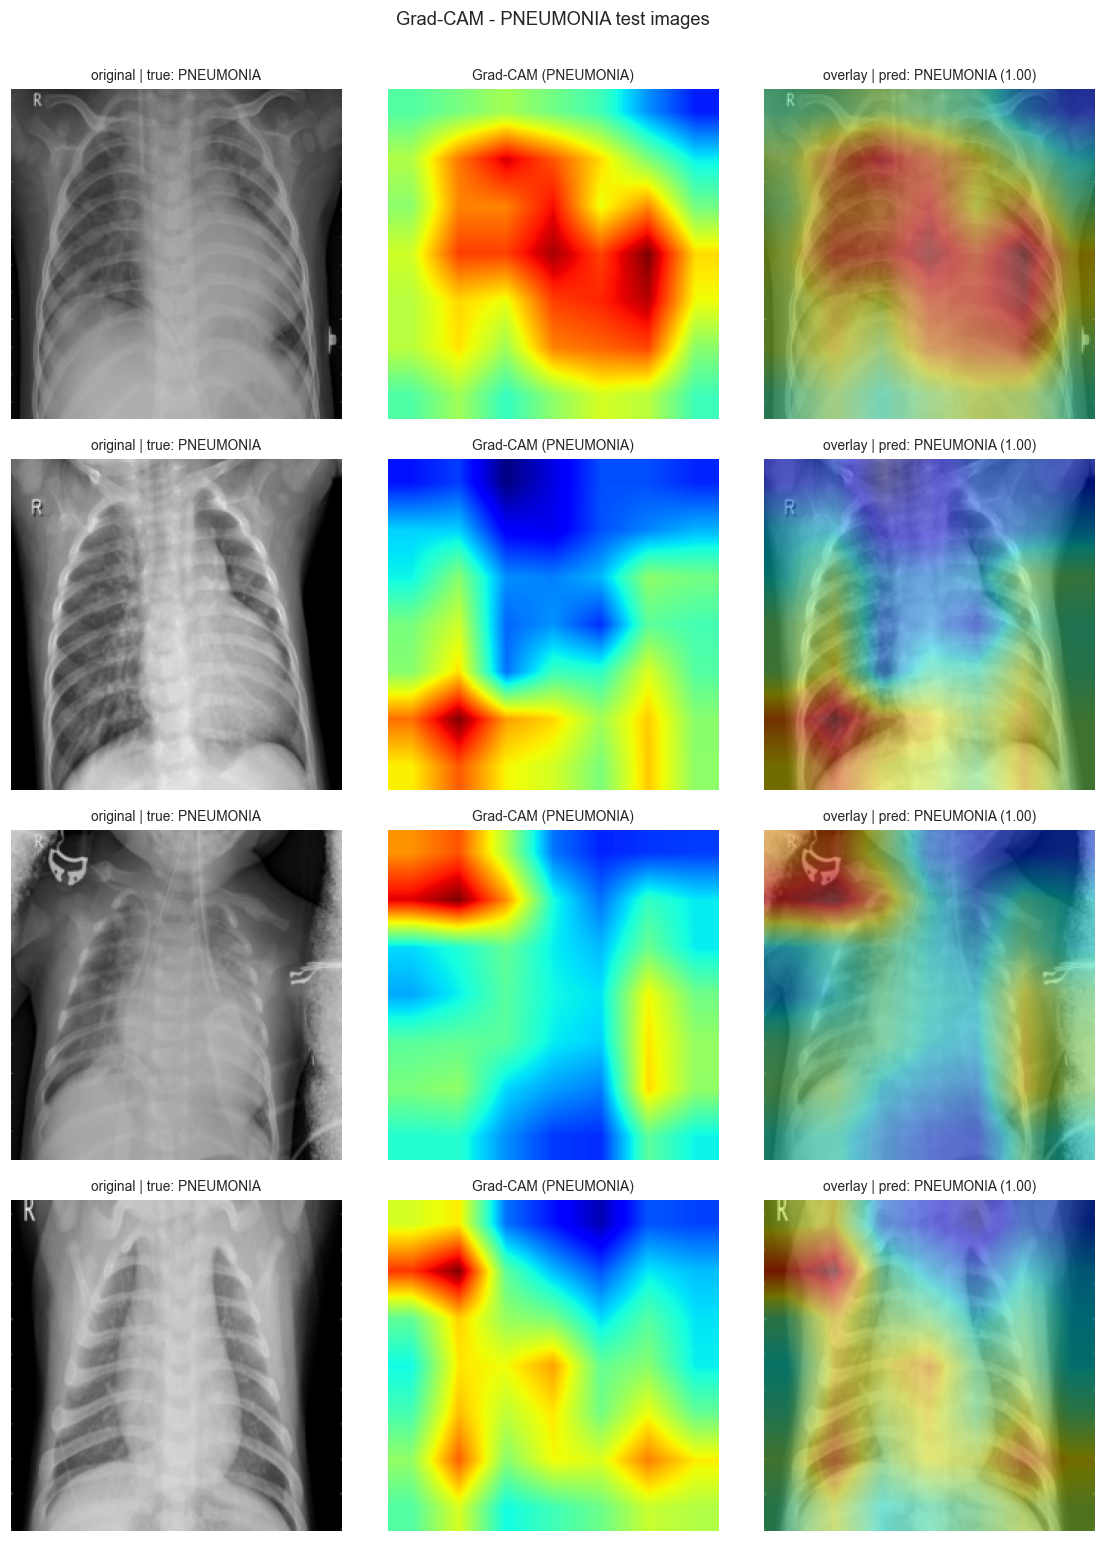

Saved C:\Users\Vibha Poojary\Downloads\Pneumonia_Detection\Pneumonia_Detection\results\gradcam\gradcam_pneumonia.png  (4/4 images)


In [29]:
def gradcam_grid(rows_df, title, save_path):
    """Original | Grad-CAM heatmap | overlay, one row per image. Errors on single images are reported, not fatal."""
    n = len(rows_df)
    fig, axes = plt.subplots(n, 3, figsize=(10.5, 3.5 * n), squeeze=False)
    failures, successes = [], 0
    for r, (_, row) in enumerate(rows_df.iterrows()):
        ax_o, ax_h, ax_v = axes[r]
        try:
            image = load_image_array(row["path"])
            cam, prob, info = make_gradcam_heatmap(final_model, image.astype("float32")[np.newaxis, ...])
            if info["grad_nonzero_fraction"] == 0:
                raise RuntimeError("all gradients are zero")
            cam_resized, _ = heatmap_to_rgb(cam, IMG_SIZE)
            pred_name = CLASS_NAMES[int(prob >= DECISION_THRESHOLD)]
            ax_o.imshow(image)
            ax_o.set_title(f"original | true: {row['class']}", fontsize=9)
            im = ax_h.imshow(cam_resized, cmap="jet", vmin=0, vmax=1)
            ax_h.set_title(f"Grad-CAM ({info['target_class']})", fontsize=9)
            ax_v.imshow(overlay_heatmap(image, cam, alpha=0.45))
            ax_v.set_title(f"overlay | pred: {pred_name} ({prob:.2f})", fontsize=9)
            successes += 1
        except Exception as exc:
            failures.append((row["filename"], repr(exc)))
            ax_o.text(0.5, 0.5, f"Grad-CAM failed:\n{type(exc).__name__}", ha="center", va="center", transform=ax_o.transAxes)
        for ax in (ax_o, ax_h, ax_v):
            ax.axis("off")
    fig.suptitle(title, fontsize=12, y=1.0)
    plt.tight_layout()
    fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()
    for name, err in failures:
        print("  FAILED:", name, err)
    if successes == 0:
        raise RuntimeError("Grad-CAM failed for every image in this grid - see the messages above.")
    print(f"Saved {save_path}  ({successes}/{n} images)")


N_PER_CLASS = 4
for cls in CLASS_NAMES:
    rows = test_df[test_df["class"] == cls].sample(n=N_PER_CLASS, random_state=SEED)
    gradcam_grid(rows, f"Grad-CAM - {cls} test images", GRADCAM_DIR / f"gradcam_{cls.lower()}.png")

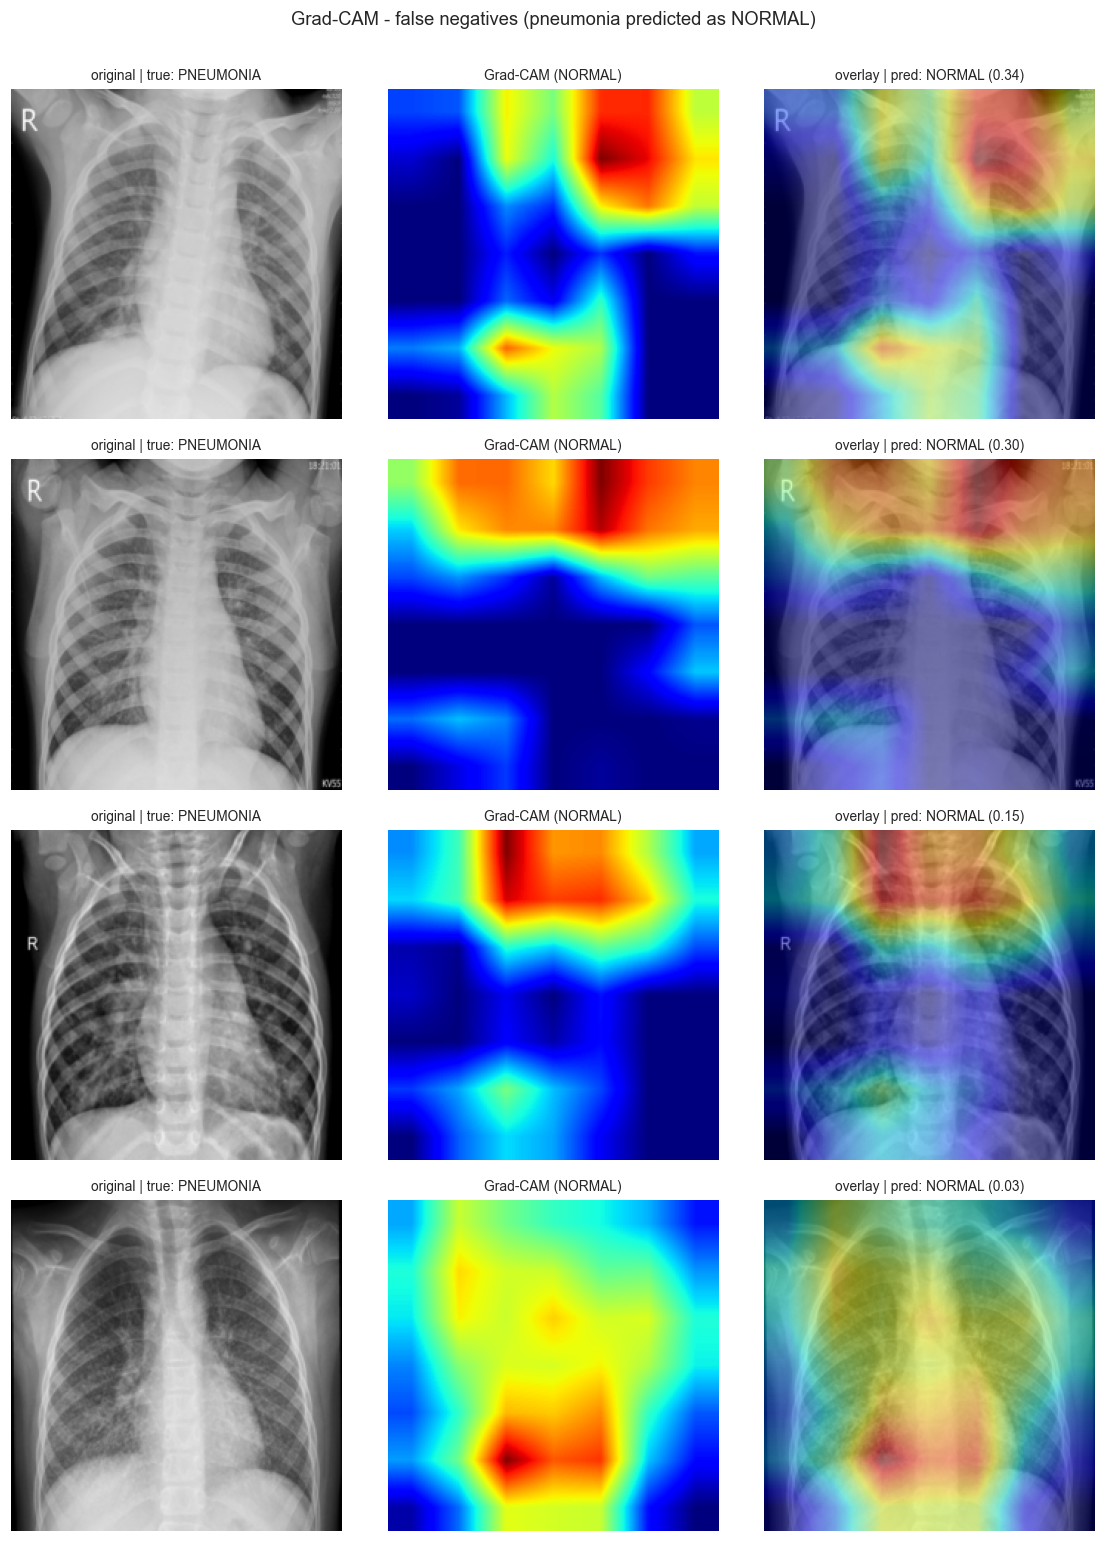

Saved C:\Users\Vibha Poojary\Downloads\Pneumonia_Detection\Pneumonia_Detection\results\gradcam\gradcam_false_negatives.png  (4/4 images)


In [30]:
# Grad-CAM for the missed pneumonia cases (false negatives), if there are any
if len(fn_df) > 0:
    gradcam_grid(fn_df.head(4), "Grad-CAM - false negatives (pneumonia predicted as NORMAL)",
                 GRADCAM_DIR / "gradcam_false_negatives.png")
else:
    print("No false negatives on the test set - nothing to show.")

## 14. Single-image prediction

`predict_xray(image_path)` (defined in `inference_utils.py`) loads an image file, converts it to RGB, resizes it to 224 x 224,
runs the model - with the **same preprocessing code as the training pipeline** - and returns / displays the predicted class and
the sigmoid output (the probability of PNEUMONIA). The Streamlit app will import this same function
(`from inference_utils import predict_xray, predict_image_bytes, get_model`).

A few test images are copied into `sample_images/` for demos (never the whole dataset).

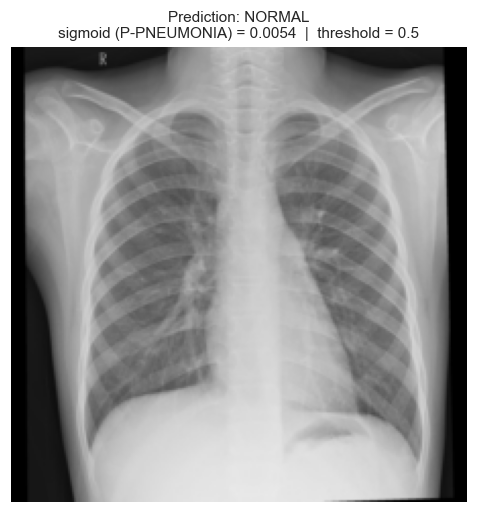

Research prototype only - not a medical diagnosis.
  file=normal_NORMAL2-IM-0007-0001.jpeg | predicted=NORMAL | sigmoid=0.0054 | confidence=0.9946



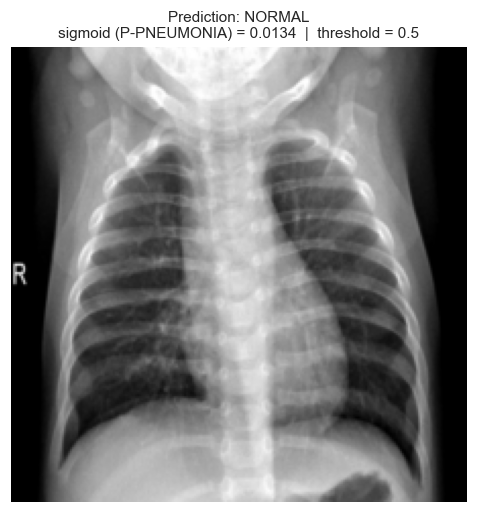

Research prototype only - not a medical diagnosis.
  file=normal_NORMAL2-IM-0346-0001.jpeg | predicted=NORMAL | sigmoid=0.0134 | confidence=0.9866



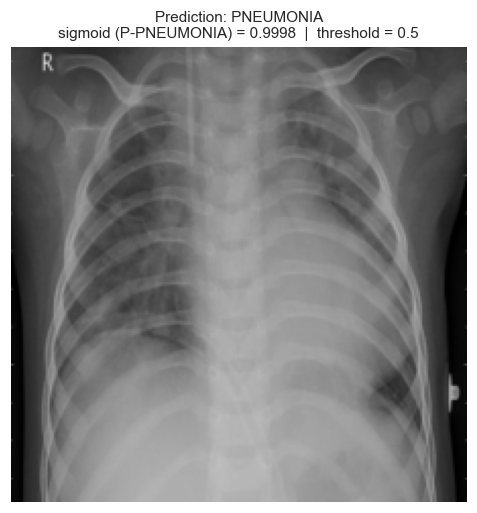

Research prototype only - not a medical diagnosis.
  file=pneumonia_person101_bacteria_485.jpeg | predicted=PNEUMONIA | sigmoid=0.9998 | confidence=0.9998



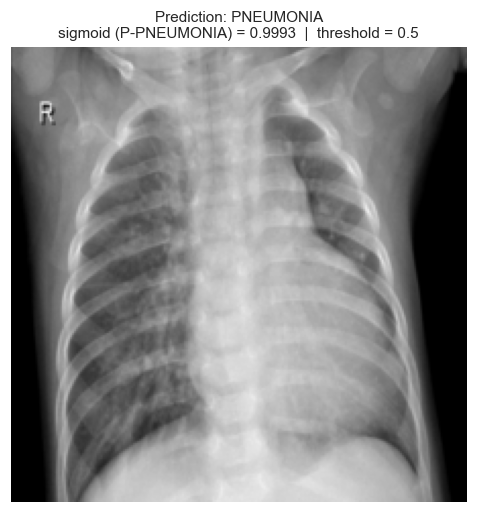

Research prototype only - not a medical diagnosis.
  file=pneumonia_person113_bacteria_543.jpeg | predicted=PNEUMONIA | sigmoid=0.9993 | confidence=0.9993

predict_xray() matches the evaluation pipeline for the demo images.


In [31]:
demo_rows = pd.concat([
    test_df[test_df["class"] == "NORMAL"].sample(n=2, random_state=SEED),
    test_df[test_df["class"] == "PNEUMONIA"].sample(n=2, random_state=SEED),
])
demo_paths = []
for _, row in demo_rows.iterrows():
    target = SAMPLE_IMAGES_DIR / f"{row['class'].lower()}_{row['filename']}"
    shutil.copy2(row["path"], target)
    demo_paths.append(target)

for path in demo_paths:
    result = predict_xray(path, model=final_model, show=True)
    print(f"  file={path.name} | predicted={result['label']} | sigmoid={result['sigmoid_output']:.4f} | confidence={result['confidence']:.4f}\n")

# Consistency check: the function must reproduce the batch predictions made through the tf.data pipeline
check_idx = [int(test_df.index[test_df["path"] == row["path"]][0]) for _, row in demo_rows.iterrows()]
for path, idx in zip(demo_paths, check_idx):
    single = predict_xray(path, model=final_model, show=False)["sigmoid_output"]
    assert abs(single - float(y_prob[idx])) < 1e-3, "predict_xray() disagrees with the evaluation pipeline"
print("predict_xray() matches the evaluation pipeline for the demo images.")

## 15. Saving artifacts and final verification

The best model was already written to `saved_models/best_pneumonia_model.keras` by `ModelCheckpoint`. Here we additionally save:
training history, class names / label mapping, model configuration (including input/output shapes), evaluation metrics, the
classification report (already saved), a model summary, and reproducibility information (versions, seed, hyper-parameters, split sizes).

Finally the model file is **reloaded with the plain `tf.keras.models.load_model()`** and its predictions are compared with the
in-memory model to prove that the custom CBAM layers are registered correctly.

In [32]:
def write_json(path, obj):
    Path(path).write_text(json.dumps(obj, indent=2, default=str), encoding="utf-8")


# 1) training history
history_df.to_csv(RESULTS_DIR / "training_history.csv")
write_json(RESULTS_DIR / "training_history.json", history_df.reset_index().to_dict(orient="list"))

# 2) class names and label mapping
write_json(SAVED_MODELS_DIR / "class_names.json", {
    "class_names": CLASS_NAMES,
    "label_mapping": CLASS_TO_INDEX,
    "positive_class": "PNEUMONIA",
    "output": "sigmoid probability of PNEUMONIA",
    "decision_threshold": DECISION_THRESHOLD,
})

# 3) model configuration
summary_lines = []
final_model.summary(print_fn=lambda line: summary_lines.append(line))
(RESULTS_DIR / "model_summary.txt").write_text("\n".join(summary_lines), encoding="utf-8")

model_config = {
    "architecture": "DenseNet121 (ImageNet) + CBAM -> GlobalAveragePooling2D -> Dropout -> Dense(1, sigmoid)",
    "model_file": str(BEST_MODEL_PATH.relative_to(PROJECT_ROOT).as_posix()),
    "input": {"shape": [None, *IMG_SIZE, 3], "dtype": "float32", "channels": "RGB", "value_range": "0-255 (normalisation is inside the model)"},
    "output": {"shape": [None, 1], "meaning": "P(PNEUMONIA), sigmoid"},
    "layer_names": {"preprocess": PREPROCESS_LAYER_NAME, "backbone": BACKBONE_NAME, "head": list(HEAD_LAYER_NAMES)},
    "custom_layers": ["DenseNetPreprocess", "ChannelAttention", "SpatialAttention", "CBAM"],
    "hyperparameters": {
        "batch_size": BATCH_SIZE, "dropout": DROPOUT_RATE, "cbam_reduction_ratio": CBAM_REDUCTION, "cbam_kernel_size": CBAM_KERNEL,
        "stage1": {"learning_rate": STAGE1_LR, "max_epochs": STAGE1_MAX_EPOCHS, "patience": STAGE1_PATIENCE},
        "stage2": {"learning_rate": STAGE2_LR, "max_epochs": STAGE2_MAX_EPOCHS, "patience": STAGE2_PATIENCE,
                   "unfrozen_from_layer_prefix": FINETUNE_FROM_PREFIX, "batchnorm_frozen": True},
        "monitor": MONITOR, "loss": "binary_crossentropy",
        "optimizer": "Adam", "class_weights": CLASS_WEIGHTS,
    },
    "parameters": {"total": int(final_model.count_params())},
    "selected_model": SELECTED_STAGE,
}
write_json(RESULTS_DIR / "model_config.json", model_config)

# 4) evaluation metrics (+ report text already saved as results/classification_report.txt)
write_json(RESULTS_DIR / "evaluation_metrics.json", test_metrics)

# 5) reproducibility information
write_json(RESULTS_DIR / "reproducibility.json", {
    "created": datetime.now().isoformat(timespec="seconds"),
    "seed": SEED,
    "python": sys.version.split()[0], "platform": platform.platform(),
    "tensorflow": tf.__version__, "keras": keras.__version__, "numpy": np.__version__,
    "pandas": pd.__version__, "scikit_learn": sklearn.__version__, "matplotlib": matplotlib.__version__,
    "gpu_available": GPU_AVAILABLE, "gpus": [g.name for g in gpus],
    "dataset": {"kaggle_handle": KAGGLE_HANDLE, "root": str(DATASET_ROOT)},
    "split": {
        "strategy": "train+val merged, exact duplicates removed, stratified + patient-grouped 80:20; test untouched",
        "train": int(len(train_df)), "validation": int(len(val_df)), "test": int(len(test_df)),
        "dev_duplicates_removed": int(dup_within_dev.sum()), "dev_images_identical_to_test_removed": int(dup_with_test.sum()),
        "split_file": "results/data_splits.csv",
    },
    "training_minutes": {"stage1": round(stage1_minutes, 2), "stage2": round(stage2_minutes, 2)},
    "epochs_run": {"stage1": int(len(history_stage1.history["loss"])), "stage2": int(len(history_stage2.history["loss"]))},
    "note": "Deterministic GPU kernels were not enforced, so re-runs can differ slightly.",
})

print("Saved:")
for p in sorted(list(RESULTS_DIR.glob("*")) + list(SAVED_MODELS_DIR.glob("*"))):
    if p.is_file():
        print(f"  {p.relative_to(PROJECT_ROOT).as_posix():48s} {p.stat().st_size / 1024:10.1f} KB")
print("  results/gradcam/:", sorted(x.name for x in GRADCAM_DIR.glob("*.png")))

Saved:
  results/.gitkeep                                        0.0 KB
  results/augmentation_preview.png                      797.5 KB
  results/class_distribution.png                         74.4 KB
  results/classification_report.txt                       0.4 KB
  results/confusion_matrix.png                           31.4 KB
  results/data_splits.csv                               730.3 KB
  results/evaluation_metrics.json                         0.4 KB
  results/model_config.json                               1.5 KB
  results/model_summary.txt                               2.9 KB
  results/precision_recall_curve.png                     55.3 KB
  results/reproducibility.json                            1.1 KB
  results/roc_curve.png                                  56.8 KB
  results/samples_normal.png                            582.6 KB
  results/samples_pneumonia.png                         475.7 KB
  results/training_accuracy.png                          78.7 KB
  results/training

In [33]:
# Reload with the plain Keras API (custom layers are registered by importing inference_utils) and compare predictions.
reloaded = tf.keras.models.load_model(str(BEST_MODEL_PATH))
probe = next(iter(test_ds))[0]
p_mem = final_model.predict(probe, verbose=0)
p_disk = reloaded.predict(probe, verbose=0)
max_diff = float(np.abs(p_mem - p_disk).max())
print(f"tf.keras.models.load_model() OK | max |prediction difference| on a test batch = {max_diff:.2e}")
assert max_diff < 1e-4, "reloaded model differs from the evaluated model"

print("\nModel file       :", BEST_MODEL_PATH, f"({BEST_MODEL_PATH.stat().st_size / 1024**2:.1f} MB)")
print("Input / output   :", reloaded.input_shape, "->", reloaded.output_shape)
print("Labels           :", CLASS_TO_INDEX, "(output = P(PNEUMONIA))")
print("\nStreamlit usage  : from inference_utils import predict_xray, predict_image_bytes, get_model")

tf.keras.models.load_model() OK | max |prediction difference| on a test batch = 0.00e+00

Model file       : C:\Users\Vibha Poojary\Downloads\Pneumonia_Detection\Pneumonia_Detection\saved_models\best_pneumonia_model.keras (46.1 MB)
Input / output   : (None, 224, 224, 3) -> (None, 1)
Labels           : {'NORMAL': 0, 'PNEUMONIA': 1} (output = P(PNEUMONIA))

Streamlit usage  : from inference_utils import predict_xray, predict_image_bytes, get_model


## Conclusion and limitations

* One architecture - **DenseNet121 + CBAM** - was trained in two stages (feature extraction, then fine-tuning with frozen BatchNorm),
  selected on a **patient-grouped, stratified validation split**, and evaluated **once** on the untouched Kaggle test set.
* The measured results are in the outputs above and in `results/` - copy the real numbers into the README and your report.
* **Limitations to discuss:** a single public dataset (paediatric patients, one institution); small and differently
  distributed test set; no external validation; threshold fixed at 0.5 (a lower threshold trades false positives for fewer missed
  pneumonia cases); Grad-CAM is a coarse visual aid and can highlight non-pathological regions; no ablation of CBAM yet
  (plain DenseNet121 vs. DenseNet121 + CBAM); not a medical device - **not suitable for clinical use**.
* **Next steps:** build the Streamlit app (`app.py`) on top of `inference_utils.py`; add the CBAM ablation and repeated runs
  with different seeds; evaluate on an external chest X-ray dataset.